# Hotel Booking Cancellation: Exploratory Data Analysis

**Project:** CS611 Machine Learning Engineering, Group 6. 

**What this notebook covers**

| Part | Sections | Question |
|---|---|---|
| A. Data foundations | 1-4 | Is the data clean, are the dates consistent, what does the target look like? |
| B. T-X framing | 5-8 | How do we define the sample and label at T-X, and how large should X be? |
| C. Rooms | 9 | Can room type tell the number of guests, and how many rooms does a booking need? |
| D. Features and leakage | 10-11 | Which features carry signal at T-X, and which ones are safe to use? |
| E. Time patterns | 12 | How do cancellations and the booking mix change over time? |
| F. Summary | 13 | Findings and open questions |

**Table of contents**

1. Setup and data loading
2. Data overview and quality
3. Data period and timeline checks
4. Target on the full data
5. Prediction setup: T-X definition and label
6. When do cancellations happen?
7. Choosing X: comparing X = 3, 7, 14 and 30
8. The T-14 sample
9. Room type, number of guests and room assumption
10. Feature patterns: full data vs T-14 sample
11. Leakage audit
12. Time patterns
13. Summary

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

# Same colour for the same thing in every chart
HOTEL_COLORS = {'H1': '#2a78d6', 'H2': '#eb6834'}
HOTEL_NAMES = {'H1': 'H1 Resort', 'H2': 'H2 City'}
LABEL_COLORS = {0: '#2a78d6', 1: '#eb6834'}
FULL_COLOR = '#9a9a9a'      # full data
TX_COLOR = '#1c5cab'        # T-X sample
X_LIST = [3, 7, 14, 30]
X_COLORS = {3: '#86b6ef', 7: '#3987e5', 14: '#1c5cab', 30: '#0d366b'}
X_MAIN = 14                 # horizon used from Section 8 onward (chosen in Section 7)

In [ ]:
from pathlib import Path

RAW = next(p / 'data' / 'raw' for p in [Path.cwd(), *Path.cwd().parents]
           if (p / 'data' / 'raw' / 'H1.csv').exists())

h1 = pd.read_csv(RAW / 'H1.csv')
h2 = pd.read_csv(RAW / 'H2.csv')

h1['hotel'] = 'H1'
h2['hotel'] = 'H2'
df = pd.concat([h1, h2], ignore_index=True)
source_cols = list(h1.columns.drop('hotel'))   # the 31 original columns

# Text columns are padded with spaces in the raw files
for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].str.strip()

print('H1 rows:', len(h1), '| H2 rows:', len(h2), '| total:', len(df))

H1 rows: 40060 | H2 rows: 79330 | total: 119390


**New columns used in this notebook**

| Column | How it is built | Meaning |
|---|---|---|
| `booking_id` | hotel + row number, e.g. `H1-000001` | Unique key for each booking |
| `arrival_date` | year + month + day of arrival | Day the guest should arrive |
| `booking_created_date` | `arrival_date - LeadTime` | Day the booking was made |
| `status_gap_days` | `arrival_date - ReservationStatusDate` | Days before arrival when the final status was set (cancel date for cancellations) |
| `total_nights` | weekend nights + week nights | Length of stay |
| `party_size` | adults + children + babies | Number of guests in the booking |

In [3]:
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
month_num = {m: i + 1 for i, m in enumerate(months)}

df['booking_id'] = df['hotel'] + '-' + (df.groupby('hotel').cumcount() + 1).astype(str).str.zfill(6)
df['arrival_date'] = pd.to_datetime(dict(year=df['ArrivalDateYear'],
                                         month=df['ArrivalDateMonth'].map(month_num),
                                         day=df['ArrivalDateDayOfMonth']))
df['booking_created_date'] = df['arrival_date'] - pd.to_timedelta(df['LeadTime'], unit='D')
df['ReservationStatusDate'] = pd.to_datetime(df['ReservationStatusDate'])
df['status_gap_days'] = (df['arrival_date'] - df['ReservationStatusDate']).dt.days
df['total_nights'] = df['StaysInWeekendNights'] + df['StaysInWeekNights']
df['party_size'] = df['Adults'] + df['Children'].fillna(0) + df['Babies']

df[['booking_id', 'hotel', 'booking_created_date', 'LeadTime', 'arrival_date',
    'ReservationStatus', 'ReservationStatusDate', 'IsCanceled']].sample(6, random_state=7)

,booking_id,hotel,booking_created_date,LeadTime,arrival_date,ReservationStatus,ReservationStatusDate,IsCanceled
71902,H2-031843,H2,2017-05-23,53,2017-07-15,Canceled,2017-05-23,1
51736,H2-011677,H2,2015-12-18,158,2016-05-24,Canceled,2016-01-18,1
101138,H2-061079,H2,2016-09-19,48,2016-11-06,Check-Out,2016-11-07,0
28656,H1-028657,H1,2015-09-19,383,2016-10-06,Check-Out,2016-10-09,0
52793,H2-012734,H2,2016-04-04,69,2016-06-12,Canceled,2016-04-27,1
56861,H2-016802,H2,2015-07-10,433,2016-09-15,Canceled,2015-10-21,1


## 2. Data overview and quality

### 2.1 Columns

In [4]:
overview = pd.DataFrame({
    'dtype': df[source_cols].dtypes.astype(str),
    'H1 unique values': df[df.hotel == 'H1'][source_cols].nunique(),
    'H2 unique values': df[df.hotel == 'H2'][source_cols].nunique(),
    'example (H1 row 1)': df[source_cols].iloc[0].astype(str),
})
overview

,dtype,H1 unique values,H2 unique values,example (H1 row 1)
IsCanceled,int64,2,2,0
LeadTime,int64,412,453,342
ArrivalDateYear,int64,3,3,2015
ArrivalDateMonth,object,12,12,July
ArrivalDateWeekNumber,int64,53,53,27
ArrivalDateDayOfMonth,int64,31,31,1
StaysInWeekendNights,int64,16,14,0
StaysInWeekNights,int64,31,29,0
Adults,int64,14,5,2
Children,float64,5,4,0.0


### 2.2 Missing values

We count real empty cells (NaN) and the text `NULL`, which the raw files use for "no agent" or "no company".

In [5]:
rows = []
for h in ['H1', 'H2']:
    d = df[df.hotel == h][source_cols]
    for c in source_cols:
        n_nan = d[c].isna().sum()
        n_null = (d[c].astype(str) == 'NULL').sum()
        if n_nan + n_null > 0:
            rows.append({'hotel': h, 'column': c, 'NaN': n_nan, '"NULL" text': n_null,
                         '% of rows': round((n_nan + n_null) / len(d) * 100, 1)})
pd.DataFrame(rows)

,hotel,column,NaN,"""NULL"" text",% of rows
0,H1,Country,464,0,1.2
1,H1,Agent,0,8209,20.5
2,H1,Company,0,36952,92.2
3,H2,Children,4,0,0.0
4,H2,Country,24,0,0.0
5,H2,Agent,0,8131,10.2
6,H2,Company,0,75641,95.3


### Observation: missing values
- **Company** is empty for 92% (H1) and 95% (H2) of bookings, and **Agent** for 21% (H1) and 10% (H2). Here `NULL` means "booked without a company or agent". It is information, not a data error. We keep it as its own category `none`.
- **Country** has 464 empty cells in H1 and 24 in H2. **Children** has 4 empty cells in H2 (filled with 0).
- No other column has missing values. Overall the data is clean.

### 2.3 ADR, guests and duplicate rows

In [6]:
rows = []
for h in ['H1', 'H2']:
    d = df[df.hotel == h]
    rows.append({'hotel': h,
                 'ADR < 0': (d.ADR < 0).sum(),
                 'ADR = 0': (d.ADR == 0).sum(),
                 'ADR > 500': (d.ADR > 500).sum(),
                 'ADR max': d.ADR.max(),
                 'party_size = 0': (d.party_size == 0).sum(),
                 'total_nights = 0': (d.total_nights == 0).sum(),
                 'rows identical to another row': d.duplicated(subset=source_cols, keep=False).sum(),
                 '% identical': round(d.duplicated(subset=source_cols, keep=False).mean() * 100, 1)})
pd.DataFrame(rows).set_index('hotel')

,ADR < 0,ADR = 0,ADR > 500,ADR max,party_size = 0,total_nights = 0,rows identical to another row,% identical
hotel,,,,,,,,
H1,1,751,1,508.0,13,384,8417,21.0
H2,0,1208,2,5400.0,167,331,31748,40.0


### Observation: ADR, guests and duplicates
- **ADR**: one negative value (H1), about 2,000 bookings with ADR = 0 (free or complimentary stays) and one extreme value of 5,400 in H2. These need a cleaning rule in the pipeline (for example cap at a high percentile).
- **180 bookings have 0 guests** (13 in H1, 167 in H2). These are data errors or placeholder bookings. Flag them in data validation.
- **715 bookings have 0 nights** (day use). Keep them, they are real bookings.
- **21% of H1 rows and 40% of H2 rows are identical to another row** in all 31 columns. The data has no booking reference, so we cannot tell a real duplicate from several rooms booked together. We keep them as separate bookings and do not build any group feature from them.

## 3. Data period and timeline checks

Before we build the T-X sample on these dates, we check that the dates are consistent. In the pipeline these checks become automated data validation rules.

In [7]:
period = df.groupby('hotel').agg(first_arrival=('arrival_date', 'min'),
                                 last_arrival=('arrival_date', 'max'),
                                 first_booking_created=('booking_created_date', 'min'),
                                 last_booking_created=('booking_created_date', 'max'))
period

,first_arrival,last_arrival,first_booking_created,last_booking_created
hotel,,,,
H1,2015-07-01,2017-08-31,2013-06-24,2017-08-31
H2,2015-07-01,2017-08-31,2014-10-17,2017-08-30


In [8]:
canc = df[df.ReservationStatus == 'Canceled']
noshow = df[df.ReservationStatus == 'No-Show']
stay = df[df.ReservationStatus == 'Check-Out']

checks = pd.DataFrame([
    ['booking_id is unique', df.booking_id.duplicated().sum(), len(df)],
    ['created date <= arrival date', (df.booking_created_date > df.arrival_date).sum(), len(df)],
    ['Canceled: cancel date <= arrival date', (canc.status_gap_days < 0).sum(), len(canc)],
    ['Canceled: cancel date >= created date', (canc.ReservationStatusDate < canc.booking_created_date).sum(), len(canc)],
    ['No-Show: status date = arrival date', (noshow.status_gap_days != 0).sum(), len(noshow)],
    ['Check-Out: status date = arrival + nights', (stay.status_gap_days != -stay.total_nights).sum(), len(stay)],
], columns=['check', 'rows that fail', 'rows checked'])
checks

,check,rows that fail,rows checked
0,booking_id is unique,0,119390
1,created date <= arrival date,0,119390
2,Canceled: cancel date <= arrival date,0,43017
3,Canceled: cancel date >= created date,0,43017
4,No-Show: status date = arrival date,1,1207
5,Check-Out: status date = arrival + nights,27,75166


### Observation: dates
- Arrivals run from **1 July 2015 to 31 August 2017** for both hotels. Booking created dates go back to **June 2013 (H1)** and **October 2014 (H2)**, because some guests book more than a year ahead.
- `booking_id` is unique and every booking is created on or before its arrival date.
- **No cancellation is dated after arrival or before the booking was made.** This is the key check: it means the T-X rule in Section 5 can be applied safely.
- Only **28 rows out of 119,390** fail a check: 1 no-show dated 111 days before arrival and 27 check-outs that do not match arrival + nights. These are tiny data entry issues. In the pipeline they become warnings, not failures.

### 3.1 Bookings per arrival month

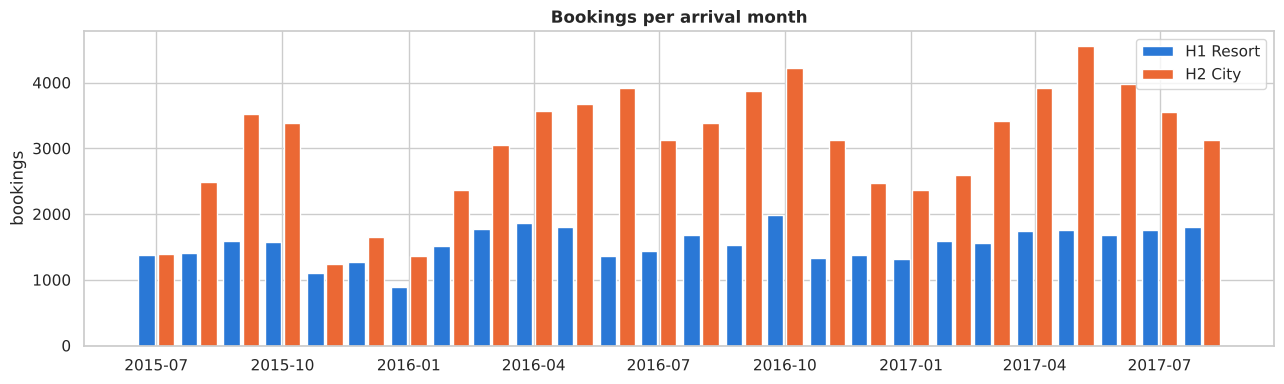

In [9]:
monthly = df.groupby(['hotel', pd.Grouper(key='arrival_date', freq='MS')]).size().unstack(0)

fig, ax = plt.subplots(figsize=(13, 4))
w = 12
ax.bar(monthly.index - pd.Timedelta(days=7), monthly['H1'], width=w, color=HOTEL_COLORS['H1'], label=HOTEL_NAMES['H1'])
ax.bar(monthly.index + pd.Timedelta(days=7), monthly['H2'], width=w, color=HOTEL_COLORS['H2'], label=HOTEL_NAMES['H2'])
ax.set_title('Bookings per arrival month', fontweight='bold')
ax.set_ylabel('bookings')
ax.legend()
plt.tight_layout()
plt.show()

### Observation: bookings per arrival month
- **H1 (Resort)** is seasonal with a summer peak and a winter low, as expected for a beach destination.
- **H2 (City)** has much more volume from spring to autumn, but **July and August 2015 are far lower** than the same months in 2016 (1,398 and 2,480 vs 3,131 and 3,378 in 2016). The City hotel data looks incomplete at the start. See the warning in Section 8.
- 2015 and 2017 are partial years (6 and 8 months). Yearly totals must not be compared directly.

### 3.2 Late bookings (made close to arrival)

A booking made fewer than X days before arrival does not exist yet at T-X, so it can never be scored.

In [10]:
rows = []
for h in ['H1', 'H2']:
    d = df[df.hotel == h]
    rows.append({'hotel': h,
                 'same-day bookings (LeadTime = 0)': round((d.LeadTime == 0).mean() * 100, 1),
                 'LeadTime < 3': round((d.LeadTime < 3).mean() * 100, 1),
                 'LeadTime < 7': round((d.LeadTime < 7).mean() * 100, 1),
                 'LeadTime < 14': round((d.LeadTime < 14).mean() * 100, 1),
                 'LeadTime < 30': round((d.LeadTime < 30).mean() * 100, 1),
                 'median LeadTime': d.LeadTime.median()})
print('% of bookings made fewer than X days before arrival')
pd.DataFrame(rows).set_index('hotel')

% of bookings made fewer than X days before arrival


,same-day bookings (LeadTime = 0),LeadTime < 3,LeadTime < 7,LeadTime < 14,LeadTime < 30,median LeadTime
hotel,,,,,,
H1,8.1,14.4,20.9,27.7,37.7,57.0
H2,3.9,7.7,12.7,18.5,28.9,74.0


### Observation: late bookings
- Many bookings are made close to arrival: **21% (H1) and 13% (H2) fewer than 7 days ahead**, and **28% (H1) and 19% (H2) fewer than 14 days ahead**. 8% of H1 bookings are same-day bookings.
- A booking made fewer than X days before arrival does not exist at T-X, so a T-X model never scores it. The larger X is, the more late bookings fall outside the model.
- The business report must say clearly which bookings are covered by the model.

## 4. Target on the full data

`IsCanceled = 1` covers two final statuses: **Canceled** and **No-Show**. `IsCanceled = 0` is **Check-Out** (a completed stay). This is the raw rate before any T-X filter.

In [11]:
status = pd.crosstab(df.hotel, df.ReservationStatus)
status['total'] = status.sum(axis=1)
status['IsCanceled rate %'] = (df.groupby('hotel').IsCanceled.mean() * 100).round(1)
status

ReservationStatus,Canceled,Check-Out,No-Show,total,IsCanceled rate %
hotel,,,,,
H1,10831,28938,291,40060,27.8
H2,32186,46228,916,79330,41.7


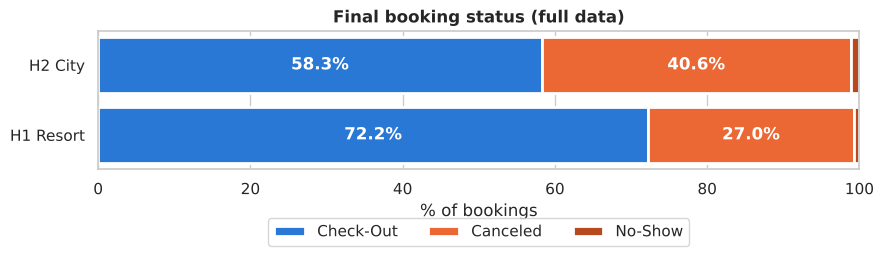

In [12]:
share = pd.crosstab(df.hotel, df.ReservationStatus, normalize='index') * 100
share = share[['Check-Out', 'Canceled', 'No-Show']]

fig, ax = plt.subplots(figsize=(9, 3))
left = np.zeros(2)
colors = {'Check-Out': LABEL_COLORS[0], 'Canceled': LABEL_COLORS[1], 'No-Show': '#b8481d'}
for s in share.columns:
    ax.barh([HOTEL_NAMES[h] for h in share.index], share[s], left=left, color=colors[s],
            label=s, edgecolor='white', linewidth=2)
    for i, v in enumerate(share[s]):
        if v > 3:
            ax.text(left[i] + v / 2, i, f'{v:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    left = left + share[s].values
ax.set_xlim(0, 100)
ax.set_xlabel('% of bookings')
ax.set_title('Final booking status (full data)', fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3)
plt.tight_layout()
plt.show()

### Observation: target on the full data
- The raw cancellation rate is **27.8% for H1 and 41.7% for H2**. H2 cancels much more, which supports separate models per hotel.
- **No-shows are rare**: 291 (H1) and 916 (H2), about 1% of bookings.
- These rates are **not** the rates a T-X model will see. Many cancellations happen long before arrival and are removed by the T-X rule (Sections 5 and 6).

## 5. Prediction setup: T-X definition and label

### 5.1 Four dates for every booking

| Date | Column | Meaning |
|---|---|---|
| Booking created | `booking_created_date` = `arrival_date - LeadTime` | When the booking enters the system |
| **Cutoff (T-X)** | `arrival_date - X days` | **The day we score the booking.** We may only use what is known on this day |
| Final status date | `ReservationStatusDate` | Day of cancellation, no-show or check-out |
| Arrival | `arrival_date` | Day the guest should arrive |

X is a parameter. Section 7 compares X = 3, 7, 14 and 30.

### 5.2 Rule: which bookings are scored at T-X

A booking is in the T-X sample only if **both** are true:

1. It was **created on or before the cutoff**: `LeadTime >= X`.
2. It was **still active at the cutoff**: it was not cancelled (or marked no-show) on or before the cutoff date.

### 5.3 Label

| Final status | When | In sample? | Label |
|---|---|---|---|
| Check-Out | after arrival | yes | **0** (completed stay) |
| Canceled | after the cutoff | yes | **1** |
| No-Show | on arrival day | yes | **1** |
| Canceled | on or before the cutoff | **no**, already gone when we score | none |
| any | booking created after the cutoff | **no**, does not exist yet when we score | none |

`ReservationStatus` and `ReservationStatusDate` are used **only** to build the sample and the label. They are never model features.

**Example (from the 10/5 meeting) with X = 7:** arrival on 20 Oct, so the cutoff is 13 Oct. A cancellation on 17 Oct stays in the sample (label 1). A cancellation on 10 Oct is excluded. A booking created on 15 Oct is also excluded.

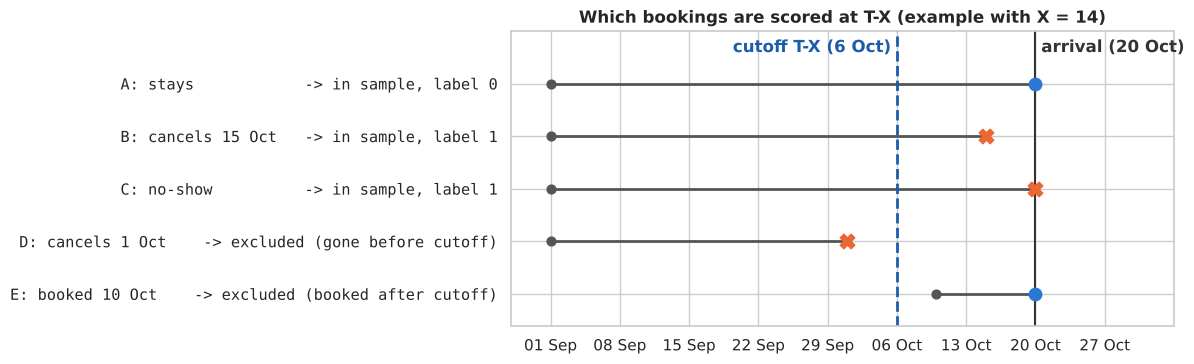

In [13]:
# Five example bookings, all arriving on 20 Oct 2016
X_EXAMPLE = 14
ex = pd.DataFrame({
    'booking':      ['A', 'B', 'C', 'D', 'E'],
    'created':      ['2016-09-01', '2016-09-01', '2016-09-01', '2016-09-01', '2016-10-10'],
    'final_status': ['Check-Out', 'Canceled', 'No-Show', 'Canceled', 'Check-Out'],
    'status_date':  ['2016-10-23', '2016-10-15', '2016-10-20', '2016-10-01', '2016-10-23'],
})
ex['arrival'] = pd.Timestamp('2016-10-20')
ex['created'] = pd.to_datetime(ex['created'])
ex['status_date'] = pd.to_datetime(ex['status_date'])
cutoff = ex['arrival'][0] - pd.Timedelta(days=X_EXAMPLE)

fig, ax = plt.subplots(figsize=(12, 3.8))
for i, r in ex.iterrows():
    y = 4 - i
    end = min(r.status_date, r.arrival) if r.final_status != 'Check-Out' else r.arrival
    ax.plot([r.created, end], [y, y], color='#555', lw=2)
    ax.scatter(r.created, y, color='#555', s=40, zorder=3)
    if r.final_status != 'Check-Out':
        ax.scatter(r.status_date, y, marker='X', s=110, color=LABEL_COLORS[1], zorder=3)
    else:
        ax.scatter(r.arrival, y, marker='o', s=80, color=LABEL_COLORS[0], zorder=3)
ax.axvline(cutoff, color=TX_COLOR, lw=2, ls='--')
ax.axvline(ex['arrival'][0], color='#333', lw=1.5)
ax.text(cutoff, 4.6, 'cutoff T-X (6 Oct) ', color=TX_COLOR, fontweight='bold', ha='right')
ax.text(ex['arrival'][0], 4.6, ' arrival (20 Oct)', color='#333', fontweight='bold', ha='left')
labels = ['A: stays            -> in sample, label 0',
          'B: cancels 15 Oct   -> in sample, label 1',
          'C: no-show          -> in sample, label 1',
          'D: cancels 1 Oct    -> excluded (gone before cutoff)',
          'E: booked 10 Oct    -> excluded (booked after cutoff)']
ax.set_yticks([4, 3, 2, 1, 0])
ax.set_yticklabels(labels, family='monospace')
ax.set_ylim(-0.6, 5)
ax.set_xlim(pd.Timestamp('2016-08-28'), pd.Timestamp('2016-11-03'))
ax.set_xticks(pd.date_range('2016-09-01', '2016-11-01', freq='7D'))
ax.set_xticklabels([d.strftime('%d %b') for d in pd.date_range('2016-09-01', '2016-11-01', freq='7D')])
ax.set_title('Which bookings are scored at T-X (example with X = 14)', fontweight='bold')
plt.tight_layout()
plt.show()

### 5.4 The rule in code

One small function builds the T-X sample for any X. The same function is used for every X in Section 7 and later in the pipeline.

In [14]:
def build_tx(data, X):
    cutoff = data['arrival_date'] - pd.Timedelta(days=X)
    booked_by_cutoff = data['LeadTime'] >= X
    ended_by_cutoff = (data['ReservationStatus'].isin(['Canceled', 'No-Show'])
                       & (data['ReservationStatusDate'] <= cutoff))
    keep = booked_by_cutoff & ~ended_by_cutoff
    out = data[keep].copy()
    out['cutoff_date'] = cutoff[keep]
    return out

# Check the function on the five examples above
ex_check = ex.rename(columns={'arrival': 'arrival_date', 'final_status': 'ReservationStatus',
                              'status_date': 'ReservationStatusDate'})
ex_check['LeadTime'] = (ex_check['arrival_date'] - ex_check['created']).dt.days
print(f'Bookings kept with X = {X_EXAMPLE}:', list(build_tx(ex_check, X_EXAMPLE)['booking']))

Bookings kept with X = 14: ['A', 'B', 'C']


## 6. When do cancellations happen?

For each cancelled booking, `status_gap_days` = days between the cancellation and arrival. A cancellation made before T-X is already gone when we score, so the model never sees it.

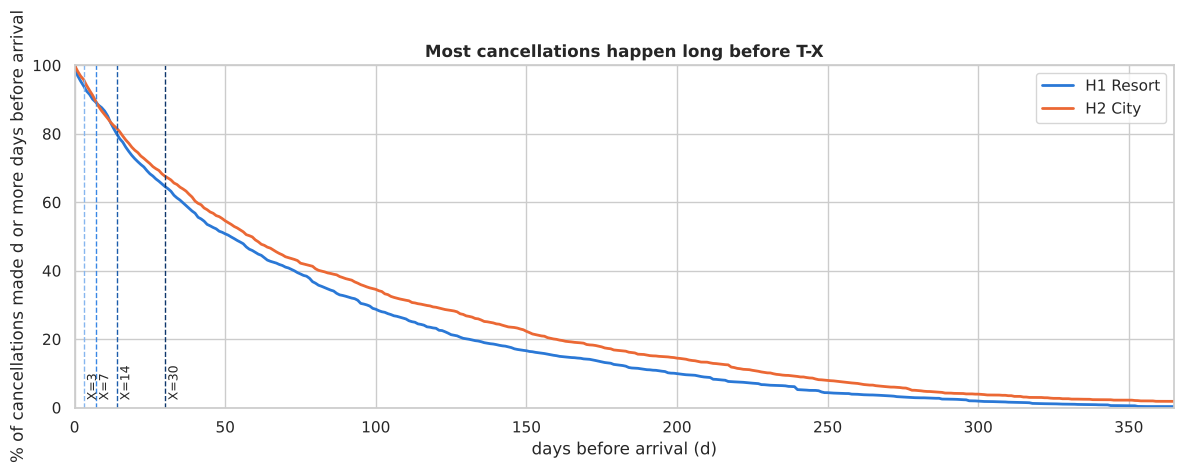

,median days before arrival,% in last 3 days,% in last 7 days,% in last 14 days,% in last 30 days
hotel,,,,,
H1,51.0,6.0,10.8,20.1,35.4
H2,58.0,4.2,10.5,18.4,32.4


In [15]:
days = np.arange(0, 366)
fig, ax = plt.subplots(figsize=(12, 4.5))
for h in ['H1', 'H2']:
    gaps = canc[canc.hotel == h].status_gap_days
    share_left = [(gaps >= d).mean() * 100 for d in days]
    ax.plot(days, share_left, color=HOTEL_COLORS[h], lw=2, label=HOTEL_NAMES[h])
for x in X_LIST:
    ax.axvline(x, color=X_COLORS[x], ls='--', lw=1)
    ax.text(x + 1, 3, f'X={x}', rotation=90, fontsize=9)
ax.set_xlim(0, 365)
ax.set_ylim(0, 100)
ax.set_xlabel('days before arrival (d)')
ax.set_ylabel('% of cancellations made d or more days before arrival')
ax.set_title('Most cancellations happen long before T-X', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

rows = []
for h in ['H1', 'H2']:
    gaps = canc[canc.hotel == h].status_gap_days
    r = {'hotel': h, 'median days before arrival': gaps.median()}
    for x in X_LIST:
        r[f'% in last {x} days'] = round((gaps < x).mean() * 100, 1)
    rows.append(r)
pd.DataFrame(rows).set_index('hotel')

### Observation: cancellation timing
- The **median cancellation happens 51 days (H1) and 58 days (H2) before arrival**.
- Only **4 to 6%** of cancellations happen in the last 3 days, **about 11%** in the last 7 days, **18 to 20%** in the last 14 days and **32 to 35%** in the last 30 days.
- So a T-X model does not try to predict all cancellations. It targets the **late ones**, which are the hardest for the hotel to resell. The report should say this clearly so the business value is not overstated.

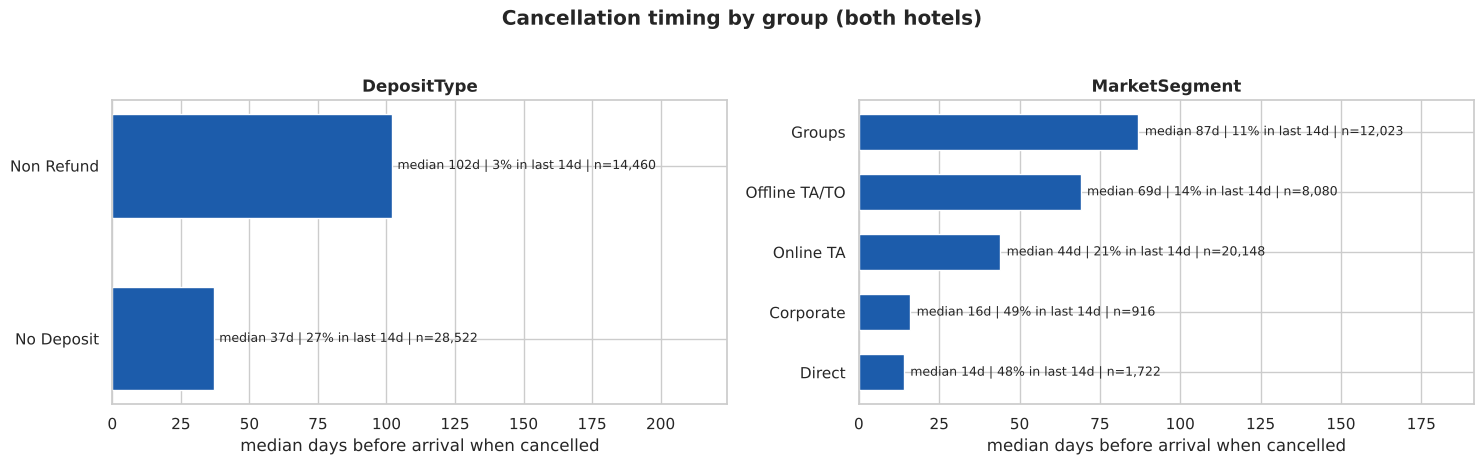

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ['DepositType', 'MarketSegment']):
    t = canc.groupby(col).status_gap_days.agg(['count', 'median'])
    t['% in last 14 days'] = canc.assign(late=canc.status_gap_days < 14).groupby(col).late.mean() * 100
    t = t[t['count'] >= 100].sort_values('median')
    ax.barh(t.index, t['median'], color=TX_COLOR, height=0.6)
    for i, (m, p, n) in enumerate(zip(t['median'], t['% in last 14 days'], t['count'])):
        ax.text(m + 2, i, f'median {m:.0f}d | {p:.0f}% in last 14d | n={n:,}', va='center', fontsize=9)
    ax.set_xlim(0, t['median'].max() * 2.2)
    ax.set_xlabel('median days before arrival when cancelled')
    ax.set_title(col, fontweight='bold')
plt.suptitle('Cancellation timing by group (both hotels)', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Observation: timing by group
- **Non Refund** bookings cancel very early (median **102 days** before arrival, only 3% in the last 14 days). **Groups** (87 days) and **Offline TA/TO** (69 days) also cancel early. For any X up to 30, most of them are gone before T-X.
- **Direct and Corporate** bookings cancel closest to arrival (median 14 to 16 days, **almost half in the last 14 days**). Online TA is in the middle (44 days).
- So the late cancellations that a T-X model must learn come mostly from direct, corporate and online bookings, not from group or non-refundable deals.

## 7. Choosing X: comparing X = 3, 7, 14 and 30

The same `build_tx()` function is called with each X. We compare sample size, number of positive examples, label balance and daily workload.

In [17]:
all_pos = df.groupby('hotel').IsCanceled.sum()
all_rows = df.groupby('hotel').size()
tx_by_x = {}
rows = []
for x in X_LIST:
    t = build_tx(df, x)
    tx_by_x[x] = t
    for h in ['H1', 'H2']:
        th = t[t.hotel == h]
        pos = int(th.IsCanceled.sum())
        noshows = int((th.ReservationStatus == 'No-Show').sum())
        rows.append({'X': x, 'hotel': h,
                     'rows': len(th),
                     '% of all bookings': round(len(th) / all_rows[h] * 100, 1),
                     'positives (label 1)': pos,
                     'positive rate %': round(th.IsCanceled.mean() * 100, 1),
                     '% of positives that are no-shows': round(noshows / pos * 100, 1),
                     '% of all cancels + no-shows still catchable': round(pos / all_pos[h] * 100, 1),
                     'median positives per arrival month': th.groupby(th.arrival_date.dt.to_period('M')).IsCanceled.sum().median()})
x_table = pd.DataFrame(rows).set_index(['X', 'hotel'])
x_table

rows  % of all bookings  positives (label 1)  positive rate %  % of positives that are no-shows  % of all cancels + no-shows still catchable  median positives per arrival month
X  hotel                                                                                                                                                                                   
3  H1     24111               60.2                  612              2.5                              35.1                                          5.5                                25.0
   H2     42385               53.4                 1628              3.8                              46.1                                          4.9                                61.0
7  H1     22028               55.0                  927              4.2                              20.8                                          8.3                                36.0
   H2     40465               51.0                 3085              7.6                              21.9                                          9.3                               114.0
14 H1     20305               50.7                 1522              7.5                              10.2                                         13.7                                56.5
   H2     38352               48.3                 4543             11.8                              13.4                                         13.7                               171.0
30 H1     17943               44.8                 2199             12.3                               5.5                                         19.8                                82.0
   H2     34646               43.7                 6329             18.3                               7.7                                         19.1                               242.0

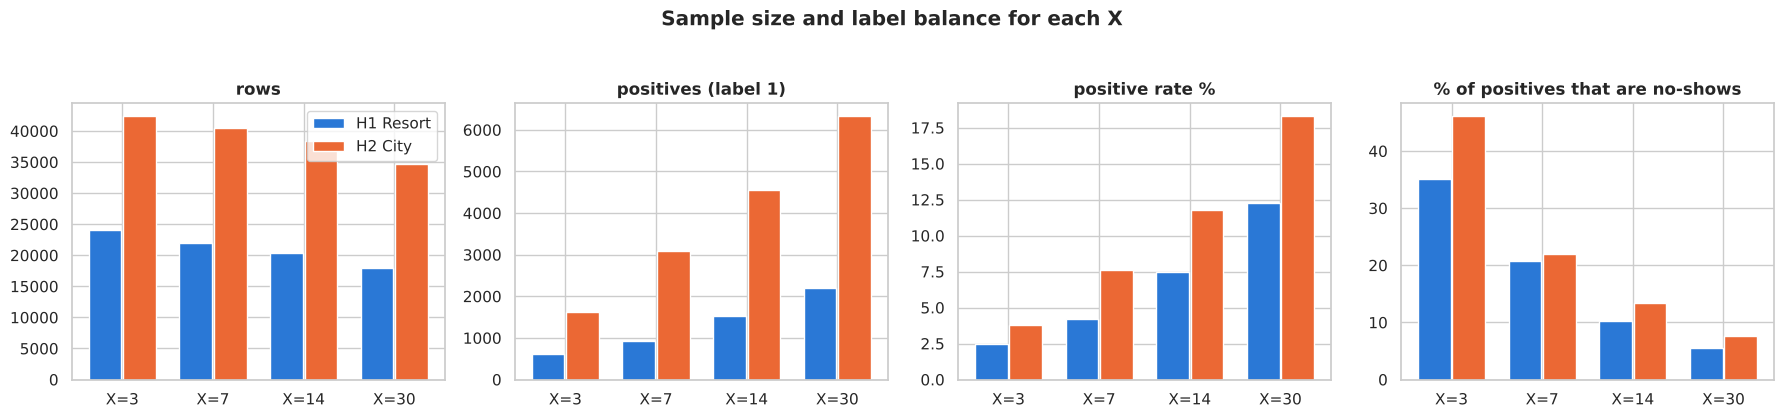

In [18]:
metrics = ['rows', 'positives (label 1)', 'positive rate %', '% of positives that are no-shows']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, metrics):
    for j, h in enumerate(['H1', 'H2']):
        vals = [x_table.loc[(x, h), m] for x in X_LIST]
        pos = np.arange(len(X_LIST)) + (j - 0.5) * 0.38
        ax.bar(pos, vals, width=0.36, color=HOTEL_COLORS[h], label=HOTEL_NAMES[h])
    ax.set_xticks(range(len(X_LIST)))
    ax.set_xticklabels([f'X={x}' for x in X_LIST])
    ax.set_title(m, fontweight='bold')
axes[0].legend()
plt.suptitle('Sample size and label balance for each X', fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

### Observation: comparing X
- **X = 3 is too thin.** The positive rate is only **2.5% (H1) and 3.8% (H2)**, and **35 to 46% of the positives are no-shows**, not cancellations. H1 has a median of only **25 positives per arrival month**.
- **X = 7** is better, but H1 still has only **927 positives** in total (36 per month), and about 21% of them are no-shows.
- **X = 14** gives **1,522 positives for H1 and 4,543 for H2** (positive rate 7.5% and 11.8%). No-shows are only 10 to 13% of positives, so the label is mainly about real cancellations.
- **X = 30** has the most positives (2,199 and 6,329), but the hotel would score bookings a month ahead, while many cancellations still happen after that point.
- From X = 3 to X = 30 the number of rows drops by only 18 to 26%, but positives grow about 3.6 to 3.9 times. **The number of positives is the real limit, not the number of rows.**

### 7.1 Daily scoring workload

Each day the pipeline scores the active bookings whose arrival is X days ahead.

In [19]:
rows = []
for x in X_LIST:
    t = tx_by_x[x]
    t = t[t.cutoff_date >= '2015-07-01']
    per_day = t.groupby(['hotel', 'cutoff_date']).size()
    for h in ['H1', 'H2']:
        s = per_day[h]
        rows.append({'X': x, 'hotel': h, 'mean per day': round(s.mean()), 'median': s.median(), 'max': s.max()})
pd.DataFrame(rows).set_index(['X', 'hotel'])

mean per day  median  max
X  hotel                           
3  H1               30    28.0  109
   H2               54    54.0  204
7  H1               28    25.0  141
   H2               52    52.0  200
14 H1               26    23.0  114
   H2               49    49.0  205
30 H1               23    20.0  124
   H2               45    43.0  207

### Observation: daily workload
- The pipeline scores about **23 to 30 bookings per day for H1 and 45 to 54 for H2**, depending on X. The peak day is about 110 to 140 (H1) and about 200 to 210 (H2).
- The workload is small and almost the same for every X. **One batch run per day is enough.** Real-time serving is not needed.

### Conclusion: we suggest X = 14

| X | Positives (H1 / H2) | No-show share of positives | Time for the hotel to act | Verdict |
|---|---|---|---|---|
| 3 | 612 / 1,628 | 35 to 46% | 3 days | Too thin, mostly no-shows |
| 7 | 927 / 3,085 | about 21% | 1 week | Possible, thin for H1 |
| **14** | **1,522 / 4,543** | **10 to 13%** | **2 weeks** | **Suggested** |
| 30 | 2,199 / 6,329 | 5 to 8% | 1 month | Most data, but scores too early |

**Why X = 14**
- Enough positive examples for both hotels (about 2.5 to 2.8 times more than X = 3).
- The label is mainly about real cancellations, not no-shows.
- Two weeks is enough time to act: reconfirm the booking, ask for a deposit, adjust overbooking or resell the room.
- About half of Direct and Corporate cancellations happen in the last 14 days, so these risky late cancellations are still ahead at T-X.

**Trade-off:** the model only covers the late cancellations, about 14% of all cancellations and no-shows. Early cancellations are already known to the hotel at the cutoff and do not need a prediction.

## 8. The T-14 sample

Based on Section 7 we use **X = 14** (`X_MAIN`) from here on. From here on, the cutoff is **T-14** (arrival date - 14 days) and the sample is called the **T-14 sample**.

### 8.1 From all bookings to the T-14 sample

In [20]:
tx = build_tx(df, X_MAIN)

rows = []
for h in ['H1', 'H2']:
    d = df[df.hotel == h]
    booked = d[d.LeadTime >= X_MAIN]
    t = tx[tx.hotel == h]
    rows.append({'hotel': h,
                 '1. all bookings': len(d),
                 '2. booked by cutoff': len(booked),
                 '3. still active at cutoff (sample)': len(t),
                 '   label 1': int(t.IsCanceled.sum()),
                 '   label 0': int((t.IsCanceled == 0).sum())})
funnel = pd.DataFrame(rows).set_index('hotel')
funnel

,1. all bookings,2. booked by cutoff,3. still active at cutoff (sample),label 1,label 0
hotel,,,,,
H1,40060,28965,20305,1522,18783
H2,79330,64618,38352,4543,33809


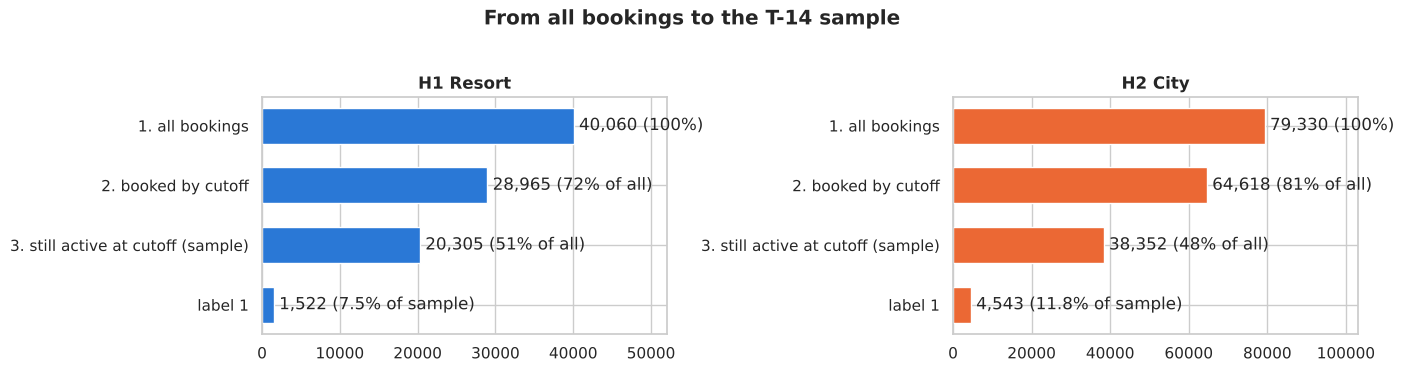

In [21]:
steps = ['1. all bookings', '2. booked by cutoff', '3. still active at cutoff (sample)', '   label 1']
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, h in zip(axes, ['H1', 'H2']):
    vals = funnel.loc[h, steps].values
    ax.barh(steps[::-1], vals[::-1], color=HOTEL_COLORS[h], height=0.6)
    notes = [f'{vals[3] / vals[2] * 100:.1f}% of sample', f'{vals[2] / vals[0] * 100:.0f}% of all',
             f'{vals[1] / vals[0] * 100:.0f}% of all', '100%']
    for i, v in enumerate(vals[::-1]):
        ax.text(v, i, f' {v:,} ({notes[i]})', va='center')
    ax.set_xlim(0, vals[0] * 1.3)
    ax.set_title(HOTEL_NAMES[h], fontweight='bold')
plt.suptitle('From all bookings to the T-14 sample', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Observation: from all bookings to the T-14 sample
- About **half of all bookings** end up in the T-14 sample: **20,305 for H1 (51%)** and **38,352 for H2 (48%)**.
- The positive rate is **7.5% (H1) and 11.8% (H2)**, much lower than 27.8% and 41.7% in the full data. The task becomes an **imbalanced classification** problem. Metrics like PR-AUC are more useful than accuracy.
- The drop from step 2 to step 3 (8,660 for H1, 26,266 for H2) is the bookings that were already cancelled at the cutoff. The model never sees them, which is correct because the hotel already knows about them.

### 8.2 Labels per hotel

In [22]:
rows = []
for h in ['H1', 'H2']:
    t = tx[tx.hotel == h]
    rows.append({'hotel': h, 'bookings': len(t),
                 'label 0 (Check-Out)': (t.ReservationStatus == 'Check-Out').sum(),
                 'label 1: Canceled': (t.ReservationStatus == 'Canceled').sum(),
                 'label 1: No-Show': (t.ReservationStatus == 'No-Show').sum(),
                 'positive rate %': round(t.IsCanceled.mean() * 100, 1)})
pd.DataFrame(rows).set_index('hotel')

,bookings,label 0 (Check-Out),label 1: Canceled,label 1: No-Show,positive rate %
hotel,,,,,
H1,20305,18783,1366,156,7.5
H2,38352,33809,3936,607,11.8


### 8.3 Volume and positive rate by arrival month

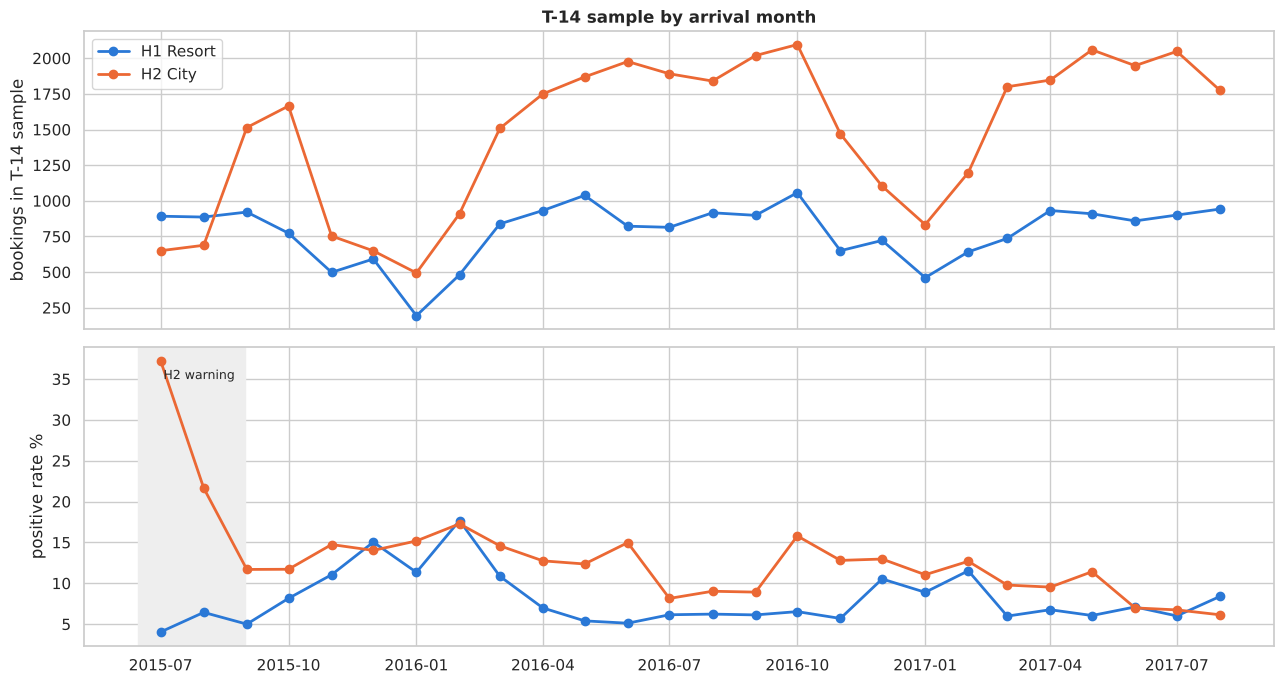

First months of H2 in the T-14 sample:
              bookings  positive rate %
arrival_date                           
2015-07-01         650             37.2
2015-08-01         688             21.7
2015-09-01        1514             11.7
2015-10-01        1665             11.7


In [23]:
m = tx.groupby(['hotel', pd.Grouper(key='arrival_date', freq='MS')]).IsCanceled.agg(['size', 'mean'])

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for h in ['H1', 'H2']:
    s = m.loc[h]
    axes[0].plot(s.index, s['size'], marker='o', color=HOTEL_COLORS[h], lw=2, label=HOTEL_NAMES[h])
    axes[1].plot(s.index, s['mean'] * 100, marker='o', color=HOTEL_COLORS[h], lw=2, label=HOTEL_NAMES[h])
axes[0].set_ylabel('bookings in T-14 sample')
axes[0].set_title('T-14 sample by arrival month', fontweight='bold')
axes[1].set_ylabel('positive rate %')
axes[1].axvspan(pd.Timestamp('2015-06-15'), pd.Timestamp('2015-08-31'), color='#eeeeee')
axes[1].text(pd.Timestamp('2015-07-03'), axes[1].get_ylim()[1] * 0.9, 'H2 warning', fontsize=9)
axes[0].legend()
plt.tight_layout()
plt.show()

print('First months of H2 in the T-14 sample:')
print((m.loc['H2'].head(4).assign(mean=lambda d: (d['mean'] * 100).round(1))
       .rename(columns={'size': 'bookings', 'mean': 'positive rate %'})))

### Observation: T-14 sample over time
- Every month has at least about **200 (H1) and 500 (H2)** bookings in the T-14 sample, so there is no empty period.
- Positive rate is higher in **winter** for H1 (up to 15 to 18% in December to February) and lower in summer (about 5 to 7%).
- **H2 warning:** July and August 2015 have a positive rate of **37.2% and 21.7%**, compared with about 12% from September 2015. Volume is also low in these months (Section 3.1). The City hotel data looks incomplete at the start. **We keep these months but flag them.** The modelling team should check their effect on training.
- H2 positive rate goes down over time (about 15% in early 2016 to 6 to 7% in summer 2017). This drift should be watched during evaluation and monitoring.

## 9. Room type, number of guests and room assumption

The data has **no column for the number of rooms** in a booking. We first check whether `ReservedRoomType` can tell us how many guests share one room. If it could, each room type would have a narrow range of party sizes.

### 9.1 Can room type tell the number of guests?

In [24]:
bins = [-1, 0, 1, 2, 3, 4, 9, 100]
names = ['0', '1', '2', '3', '4', '5-9', '10+']
df['party_group'] = pd.cut(df.party_size, bins=bins, labels=names)
party = pd.crosstab(df.party_group, df.hotel)
party['H1 %'] = (party['H1'] / party['H1'].sum() * 100).round(2)
party['H2 %'] = (party['H2'] / party['H2'].sum() * 100).round(2)
party

hotel,H1,H2,H1 %,H2 %
party_group,,,,
0,13,167,0.03,0.21
1,7013,15568,17.51,19.62
2,28116,53935,70.18,67.99
3,2789,7706,6.96,9.71
4,2069,1860,5.16,2.34
5-9,46,92,0.11,0.12
10+,14,2,0.03,0.00


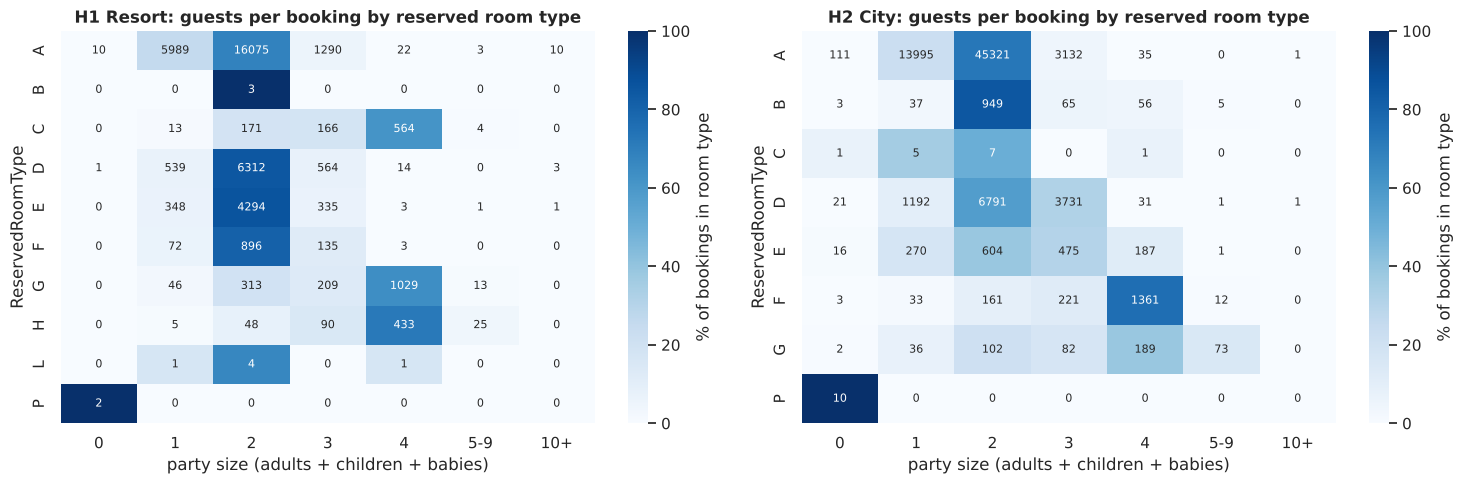

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, h in zip(axes, ['H1', 'H2']):
    d = df[df.hotel == h]
    t = pd.crosstab(d.ReservedRoomType, d.party_group)
    t_pct = t.div(t.sum(axis=1), axis=0) * 100
    sns.heatmap(t_pct, annot=t, fmt='d', cmap='Blues', cbar_kws={'label': '% of bookings in room type'}, ax=ax,
                annot_kws={'fontsize': 8})
    ax.set_title(f'{HOTEL_NAMES[h]}: guests per booking by reserved room type', fontweight='bold')
    ax.set_xlabel('party size (adults + children + babies)')
    ax.set_ylabel('ReservedRoomType')
plt.tight_layout()
plt.show()

In [26]:
room = df.groupby(['hotel', 'ReservedRoomType']).party_size.agg(['count', 'min', 'median', 'max'])
room['% with 3+ guests'] = (df.assign(big=df.party_size >= 3)
                            .groupby(['hotel', 'ReservedRoomType']).big.mean() * 100).round(1)
room

count  min  median   max  % with 3+ guests
hotel ReservedRoomType                                            
H1    A                 23399  0.0     2.0  55.0               5.7
      B                     3  2.0     2.0   2.0               0.0
      C                   918  1.0     4.0   5.0              80.0
      D                  7433  0.0     2.0  20.0               7.8
      E                  4982  1.0     2.0  10.0               6.8
      F                  1106  1.0     2.0   4.0              12.5
      G                  1610  1.0     4.0   5.0              77.7
      H                   601  1.0     4.0   5.0              91.2
      L                     6  1.0     2.0   4.0              16.7
      P                     2  0.0     0.0   0.0               0.0
H2    A                 62595  0.0     2.0  10.0               5.1
      B                  1115  0.0     2.0   5.0              11.3
      C                    14  0.0     2.0   4.0               7.1
      D                 11768  0.0     2.0  12.0              32.0
      E                  1553  0.0     2.0   5.0              42.7
      F                  1791  0.0     4.0   5.0              89.0
      G                   484  0.0     4.0   5.0              71.1
      P                    10  0.0     0.0   0.0               0.0

In [27]:
print('Bookings with 10 or more guests:')
df[df.party_size >= 10][['booking_id', 'ReservedRoomType', 'AssignedRoomType', 'Adults', 'Children',
                         'Babies', 'party_size', 'MarketSegment', 'ReservationStatus']].sort_values('party_size')

Bookings with 10 or more guests:


,booking_id,ReservedRoomType,AssignedRoomType,Adults,Children,Babies,party_size,MarketSegment,ReservationStatus
2417,H1-002418,E,E,10,0.0,0,10.0,Direct,Canceled
78656,H2-038597,A,B,1,0.0,9,10.0,Corporate,Check-Out
328,H1-000329,D,D,2,10.0,0,12.0,Offline TA/TO,No-Show
46619,H2-006560,D,D,2,0.0,10,12.0,Online TA,Check-Out
2228,H1-002229,D,D,20,0.0,0,20.0,Direct,Canceled
2418,H1-002419,D,D,20,0.0,0,20.0,Direct,Canceled
1884,H1-001885,A,A,26,0.0,0,26.0,Offline TA/TO,Canceled
1587,H1-001588,A,A,26,0.0,0,26.0,Offline TA/TO,Canceled
1752,H1-001753,A,A,26,0.0,0,26.0,Offline TA/TO,Canceled
2003,H1-002004,A,A,26,0.0,0,26.0,Offline TA/TO,Canceled


### Observation: room type does not tell the number of guests
- **The same room type holds very different party sizes.** In H1, room type **A** has bookings from **0 to 55 guests**, and room type **D** from 0 to 20. In H2, room type **D** goes from 0 to 12.
- Some room types are larger: in H1, types **C, G and H** are mostly 4 guests (78 to 91% have 3 or more). In H2, types **F and G** are mostly 4 guests. But the range inside each type is still wide.
- **16 bookings have 10 or more guests**, mostly in room type A or D. One room cannot hold 26 to 55 guests. These are **group bookings with several rooms** stored as one row.
- **Conclusion:** `ReservedRoomType` cannot be used to calculate the number of guests per room or the number of rooms. **One booking is not always one room**, so we need a room assumption (Section 9.2).

### 9.2 Room assumption based on adults

**Why adults only?** Children and babies normally stay in the same room as their parents (extra bed or cot), so they do not need their own room. Two adults per room is the standard double or twin room.

Bookings with 0 adults still need a room, so they count as 1 room. `ADULTS_PER_ROOM` is a parameter that the team can change later.

In [28]:
ADULTS_PER_ROOM = 2
df['est_rooms'] = np.ceil(df['Adults'] / ADULTS_PER_ROOM).clip(lower=1).astype(int)

rooms_tbl = pd.crosstab(df['est_rooms'].clip(upper=4).astype(str).replace('4', '4+'), df['hotel'])
rooms_tbl['H1 %'] = (rooms_tbl['H1'] / rooms_tbl['H1'].sum() * 100).round(2)
rooms_tbl['H2 %'] = (rooms_tbl['H2'] / rooms_tbl['H2'].sum() * 100).round(2)
rooms_tbl.index.name = 'estimated rooms'
rooms_tbl

hotel,H1,H2,H1 %,H2 %
estimated rooms,,,,
1,38586,74524,96.32,93.94
2,1458,4806,3.64,6.06
3,3,0,0.01,0.00
4+,13,0,0.03,0.00


In [29]:
d = df.copy()
d['zero_adults'] = d['Adults'] == 0
d['two_plus_rooms'] = d['est_rooms'] > 1
summary_rooms = d.groupby('hotel').agg(bookings=('booking_id', 'count'),
                                       estimated_rooms=('est_rooms', 'sum'),
                                       bookings_with_0_adults=('zero_adults', 'sum'),
                                       pct_needing_2plus_rooms=('two_plus_rooms', 'mean'))
summary_rooms['rooms per booking'] = (summary_rooms['estimated_rooms'] / summary_rooms['bookings']).round(3)
summary_rooms['pct_needing_2plus_rooms'] = (summary_rooms['pct_needing_2plus_rooms'] * 100).round(1)
summary_rooms

,bookings,estimated_rooms,bookings_with_0_adults,pct_needing_2plus_rooms,rooms per booking
hotel,,,,,
H1,40060,41702,13,3.7,1.041
H2,79330,84136,390,6.1,1.061


In [30]:
# Does the assumption treat families as one room?
fam = df[df.party_size >= 3].copy()
fam['has_children_or_babies'] = (fam['Children'].fillna(0) + fam['Babies']) > 0
fam['estimated_1_room'] = fam['est_rooms'] == 1
check = fam.groupby('hotel').agg(bookings_3plus_guests=('booking_id', 'count'),
                                 pct_with_children_or_babies=('has_children_or_babies', 'mean'),
                                 pct_estimated_as_1_room=('estimated_1_room', 'mean'))
check[['pct_with_children_or_babies', 'pct_estimated_as_1_room']] *= 100
check.round(1)

,bookings_3plus_guests,pct_with_children_or_babies,pct_estimated_as_1_room
hotel,,,
H1,4918,78.2,70.0
H2,9660,51.7,50.2


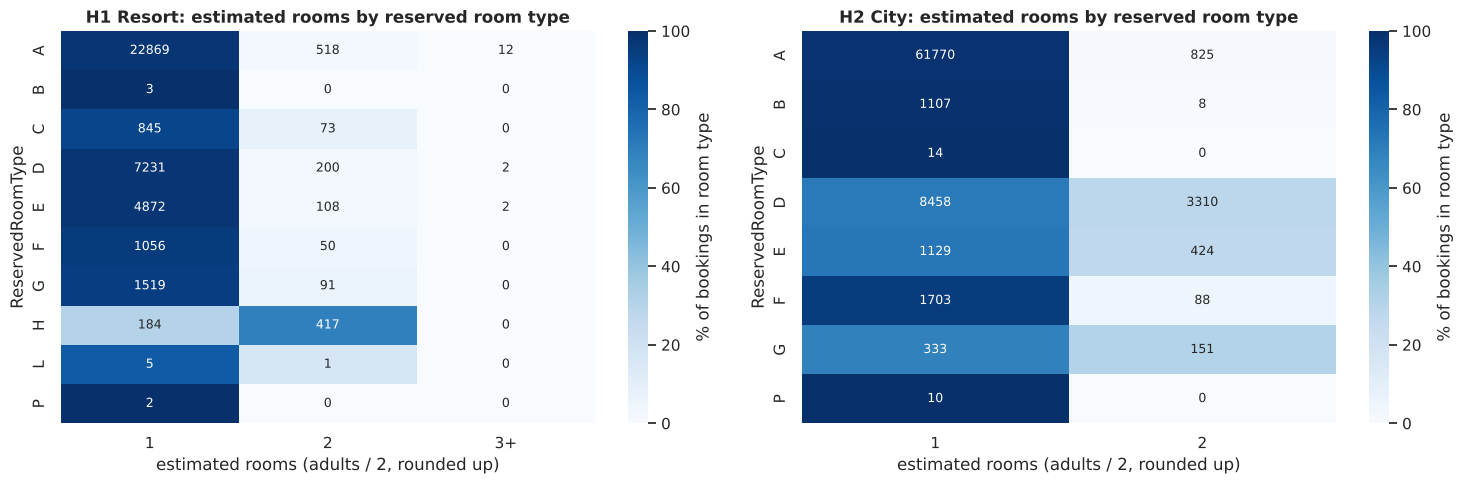

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, h in zip(axes, ['H1', 'H2']):
    d = df[df.hotel == h]
    t = pd.crosstab(d.ReservedRoomType, d.est_rooms.clip(upper=3).astype(str).replace('3', '3+'))
    t_pct = t.div(t.sum(axis=1), axis=0) * 100
    sns.heatmap(t_pct, annot=t, fmt='d', cmap='Blues', cbar_kws={'label': '% of bookings in room type'}, ax=ax,
                annot_kws={'fontsize': 9})
    ax.set_title(f'{HOTEL_NAMES[h]}: estimated rooms by reserved room type', fontweight='bold')
    ax.set_xlabel('estimated rooms (adults / 2, rounded up)')
    ax.set_ylabel('ReservedRoomType')
plt.tight_layout()
plt.show()

### Observation: room assumption
- With 2 adults per room, **96.3% of H1 bookings and 93.9% of H2 bookings need 1 room**. **3.7% (H1) and 6.1% (H2)** need 2 or more rooms.
- On average one booking = **1.04 rooms (H1)** and **1.06 rooms (H2)**. So "1 booking = 1 room" is close on average, but wrong for group bookings. The H1 booking with 55 adults becomes 28 rooms instead of 1.
- **Families stay as one room.** Among bookings with 3 or more guests, 78% (H1) and 52% (H2) include children or babies, and most of these are estimated as 1 room (70% of H1 and 50% of H2 bookings with 3+ guests).
- **Limitation:** large room types may hold 3 or 4 adults in one room. For example, H1 type **H** has 417 of 601 bookings estimated as 2 rooms, and H2 type **D** has 3,310 of 11,768. These may be one family room in reality, so the assumption can over-count rooms a little.
- **390 H2 bookings and 13 H1 bookings have 0 adults.** They are counted as 1 room and should be flagged in data validation.
- The rule is kept as a parameter (`ADULTS_PER_ROOM = 2`) so the team can test other values later, for example a different value per hotel.

## 10. Feature patterns: full data vs T-14 sample

Most cancellations happen early, so the full data is dominated by early cancellations. After the T-14 filter the population is different, and patterns can change.

We compare **lift** = (positive rate in a group) / (overall positive rate). Lift above 1 means riskier than average. We use lift because the overall rate itself is very different between the full data and the T-14 sample.

Section 10 shows patterns only. Whether a column is **allowed** at T-14 is decided in Section 11.

In [32]:
full = df.copy()
for d in [full, tx]:
    d['LeadTimeGroup'] = pd.cut(d.LeadTime, [-1, 7, 14, 30, 60, 120, 1000],
                                labels=['0-7', '8-14', '15-30', '31-60', '61-120', '>120'])
    d['SpecialRequests'] = d.TotalOfSpecialRequests.clip(upper=3).astype(str).replace('3', '3+')

def lift_table(data, col):
    base = data.IsCanceled.mean()
    g = data.groupby(col, observed=True).IsCanceled.agg(['count', 'mean'])
    g['lift'] = g['mean'] / base
    return g

### 10.1 Lead time

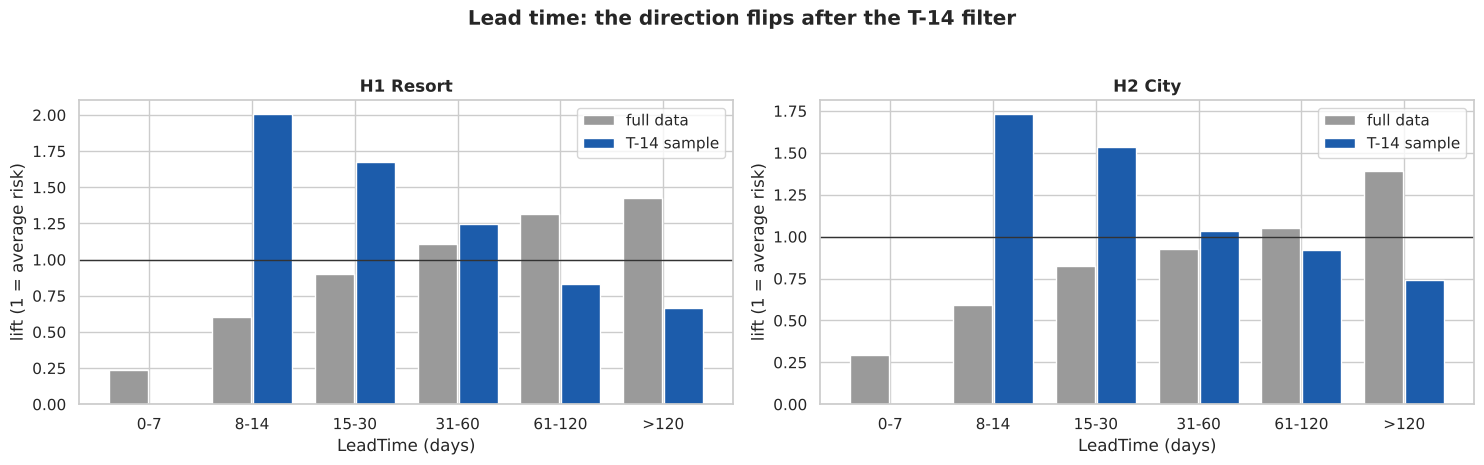

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, h in zip(axes, ['H1', 'H2']):
    a = lift_table(full[full.hotel == h], 'LeadTimeGroup')
    b = lift_table(tx[tx.hotel == h], 'LeadTimeGroup')
    pos = np.arange(len(a))
    ax.bar(pos - 0.2, a['lift'], width=0.38, color=FULL_COLOR, label='full data')
    ax.bar(pos + 0.2, b['lift'].reindex(a.index), width=0.38, color=TX_COLOR, label='T-14 sample')
    ax.axhline(1, color='#333', lw=1)
    ax.set_xticks(pos)
    ax.set_xticklabels(a.index)
    ax.set_xlabel('LeadTime (days)')
    ax.set_ylabel('lift (1 = average risk)')
    ax.set_title(HOTEL_NAMES[h], fontweight='bold')
    ax.legend()
plt.suptitle('Lead time: the direction flips after the T-14 filter', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Observation: lead time flips direction
- In the **full data**, longer lead time means **more** risk (lift 1.43 for H1 and 1.39 for H2 when LeadTime > 120).
- In the **T-14 sample** it is the **opposite**: bookings made 8 to 14 days ahead have the highest lift (**2.00 for H1, 1.73 for H2**), and LeadTime > 120 has the lowest (0.66 and 0.74).
- Reason: long-lead bookings that are still active at T-14 are the committed ones. The uncommitted ones already cancelled earlier.
- **This is the most important difference from the first EDA.** Insights from the full data do not transfer one to one. Feature analysis must be done on the T-14 sample.

### 10.2 Arrival month (seasonality)

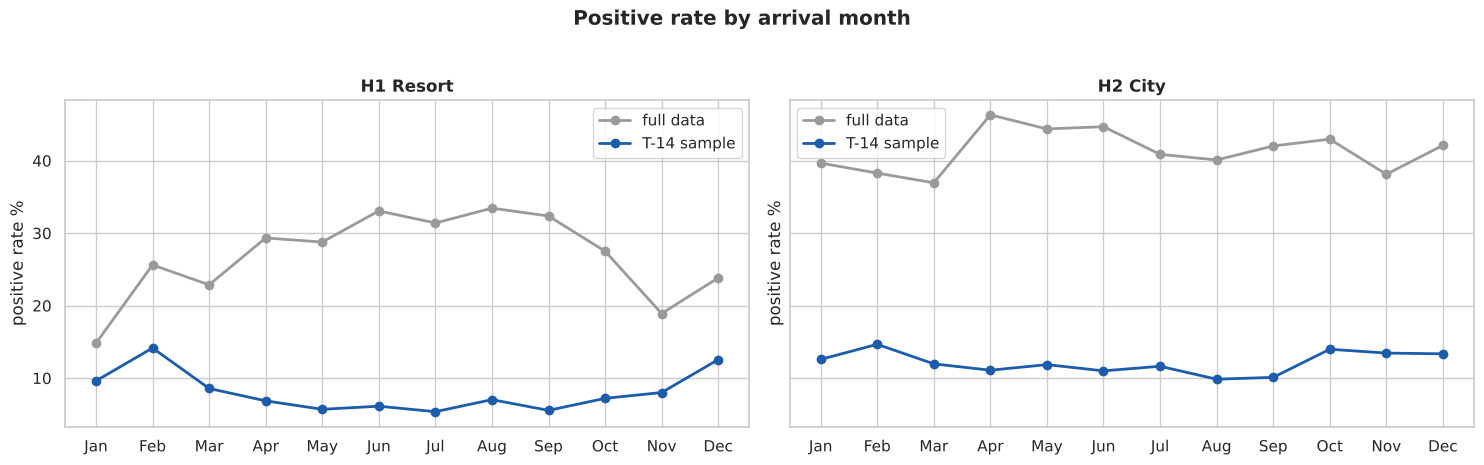

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, h in zip(axes, ['H1', 'H2']):
    a = full[full.hotel == h].groupby('ArrivalDateMonth').IsCanceled.mean().reindex(months) * 100
    b = tx[tx.hotel == h].groupby('ArrivalDateMonth').IsCanceled.mean().reindex(months) * 100
    ax.plot(range(12), a, marker='o', color=FULL_COLOR, lw=2, label='full data')
    ax.plot(range(12), b, marker='o', color=TX_COLOR, lw=2, label='T-14 sample')
    ax.set_xticks(range(12))
    ax.set_xticklabels([m[:3] for m in months])
    ax.set_ylabel('positive rate %')
    ax.set_title(HOTEL_NAMES[h], fontweight='bold')
    ax.legend()
plt.suptitle('Positive rate by arrival month', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Observation: seasonality
- **H1** in the T-14 sample: positive rate is highest in **winter** (February 14.2%, December 12.6%) and lowest in summer (about 5 to 7%). In the full data the pattern is the opposite (summer is highest). Arrival month is a useful feature, but again the T-14 view differs from the full data.
- **H2** is flatter (about 10 to 15% in every month).

### 10.3 Categorical features (both hotels)

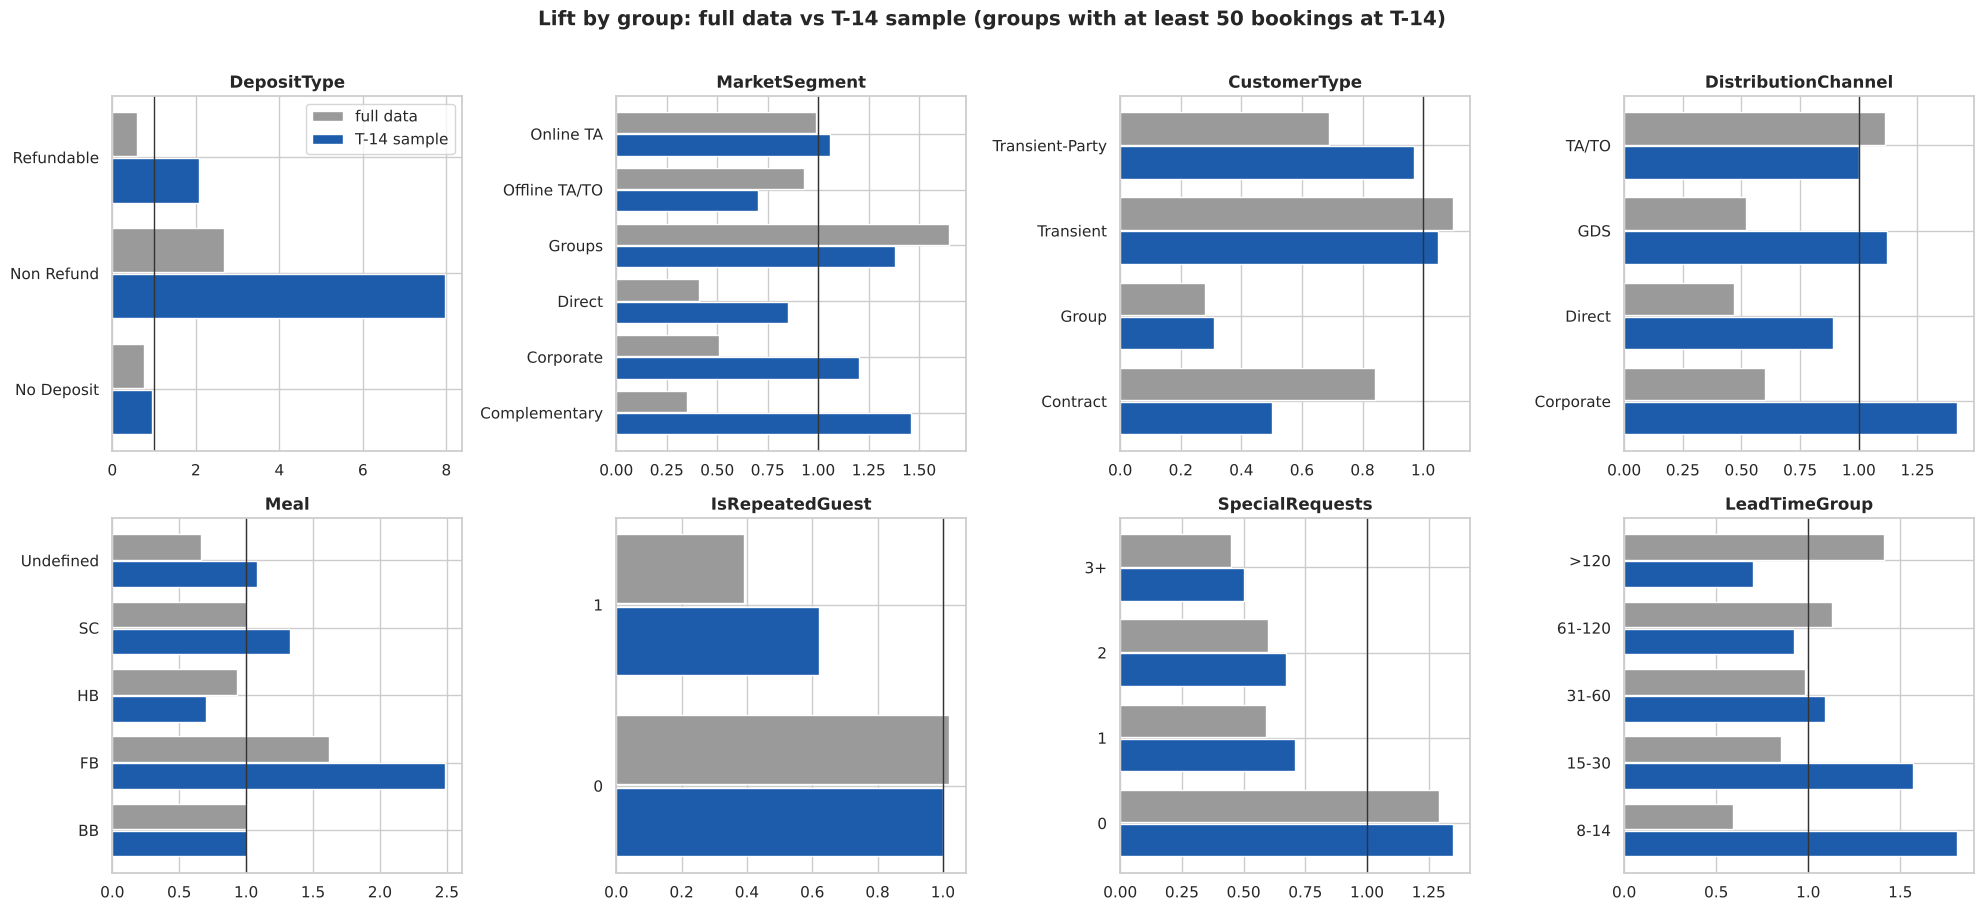

In [35]:
cat_list = ['DepositType', 'MarketSegment', 'CustomerType', 'DistributionChannel',
            'Meal', 'IsRepeatedGuest', 'SpecialRequests', 'LeadTimeGroup']
compare = {}
for col in cat_list:
    a = lift_table(full, col)
    b = lift_table(tx, col)
    compare[col] = pd.DataFrame({'n full': a['count'], 'rate full %': a['mean'] * 100, 'lift full': a['lift'],
                                 'n T-14': b['count'], 'rate T-14 %': b['mean'] * 100, 'lift T-14': b['lift']}).round(2)

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, cat_list):
    t = compare[col]
    t = t[t['n T-14'].fillna(0) >= 50]
    y = np.arange(len(t))
    ax.barh(y + 0.2, t['lift full'], height=0.38, color=FULL_COLOR, label='full data')
    ax.barh(y - 0.2, t['lift T-14'], height=0.38, color=TX_COLOR, label='T-14 sample')
    ax.axvline(1, color='#333', lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(t.index.astype(str))
    ax.set_title(col, fontweight='bold')
axes[0, 0].legend()
plt.suptitle('Lift by group: full data vs T-14 sample (groups with at least 50 bookings at T-14)', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [36]:
for col in ['DepositType', 'MarketSegment']:
    print(f'=== {col} ===')
    print(compare[col].to_string())
    print()

=== DepositType ===
             n full  rate full %  lift full  n T-14  rate T-14 %  lift T-14
DepositType                                                                
No Deposit   104641        28.38       0.77   58114         9.80       0.95
Non Refund    14587        99.36       2.68     417        82.49       7.98
Refundable      162        22.22       0.60     126        21.43       2.07

=== MarketSegment ===
               n full  rate full %  lift full   n T-14  rate T-14 %  lift T-14
MarketSegment                                                                 
Aviation          237        21.94       0.59      7.0        28.57       2.76
Complementary     743        13.06       0.35    152.0        15.13       1.46
Corporate        5295        18.73       0.51   1505.0        12.43       1.20
Direct          12606        15.34       0.41   5642.0         8.83       0.85
Groups          19811        61.06       1.65   7966.0        14.24       1.38
Offline TA/TO   24219   

### Observation: categorical features
- **DepositType changes the most.** In the full data, 14,587 bookings are Non Refund with a 99% cancel rate. At T-14 only **417** remain, because most were cancelled early. They are still very risky (82%, lift 8.0), but now they are a rare group instead of a big one.
- **MarketSegment Groups** drops from a 61% cancel rate to 14%. **Corporate** goes from low risk (lift 0.51) to above average (lift 1.20). **Offline TA/TO** becomes the safest large segment (lift 0.70).
- **CustomerType Contract** and **Group** have low risk at T-14 (lift 0.50 and 0.31). Transient is about average.
- **Repeated guests** and **guests with special requests** have lower risk in both views. Special requests is flagged as risky in Section 11.
- **Meal FB** (full board) is risky (lift 2.5) but small (349 bookings).

### 10.4 Numerical features at T-14 (mean by label)

In [37]:
num_cols = ['LeadTime', 'ADR', 'total_nights', 'Adults', 'Children', 'Babies', 'party_size',
            'PreviousCancellations', 'PreviousBookingsNotCanceled', 'TotalOfSpecialRequests',
            'BookingChanges', 'RequiredCarParkingSpaces', 'DaysInWaitingList']
num = tx.groupby(['hotel', 'IsCanceled'])[num_cols].mean().round(2).T
num

hotel                            H1             H2        
IsCanceled                        0      1       0       1
LeadTime                     119.55  87.15  108.76   90.52
ADR                           97.83  99.45  106.49  106.97
total_nights                   5.28   4.11    3.18    3.13
Adults                         1.92   1.91    1.90    1.86
Children                       0.12   0.18    0.10    0.09
Babies                         0.02   0.01    0.01    0.00
party_size                     2.05   2.11    2.00    1.96
PreviousCancellations          0.00   0.07    0.00    0.08
PreviousBookingsNotCanceled    0.06   0.04    0.05    0.02
TotalOfSpecialRequests         0.74   0.58    0.78    0.45
BookingChanges                 0.40   0.24    0.27    0.15
RequiredCarParkingSpaces       0.16   0.00    0.03    0.00
DaysInWaitingList              1.07   0.43    2.94    2.65

### Observation: numerical features at T-14
- **LeadTime** is lower for label 1 (87 vs 120 days for H1), which matches Section 10.1.
- **PreviousCancellations** is higher for label 1 in both hotels. Past behaviour of the guest is a useful signal.
- **TotalOfSpecialRequests, BookingChanges and RequiredCarParkingSpaces** are higher for label 0. Parking is **exactly 0** for every label 1 booking in both hotels. This is a warning sign for leakage (Section 11).
- **ADR, party size and number of guests** are almost the same for both labels.

### 10.5 ADR (average daily rate)

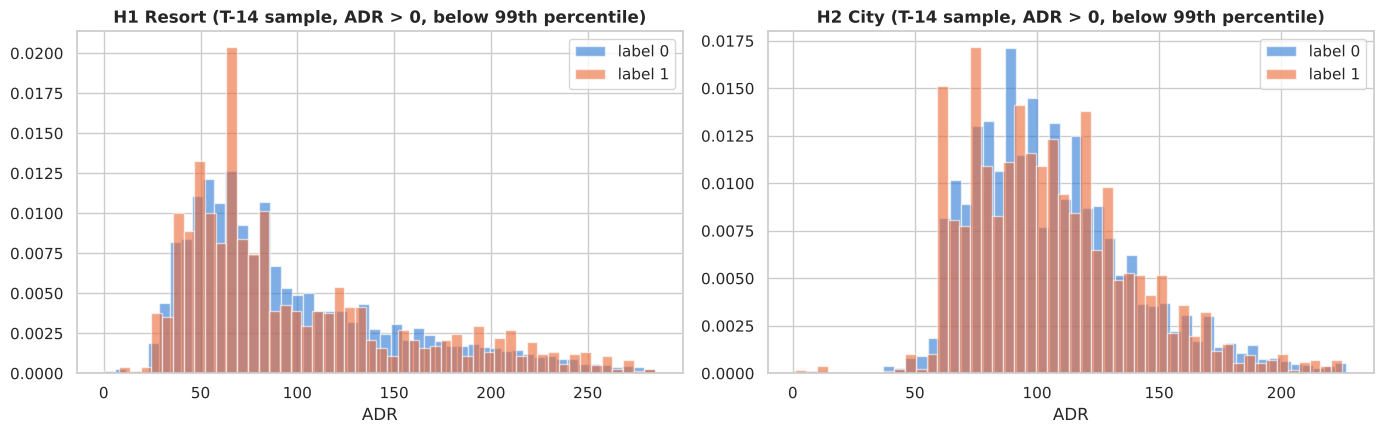

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, h in zip(axes, ['H1', 'H2']):
    t = tx[(tx.hotel == h) & (tx.ADR > 0)]
    t = t[t.ADR < t.ADR.quantile(0.99)]
    for lab in [0, 1]:
        ax.hist(t[t.IsCanceled == lab].ADR, bins=50, density=True, alpha=0.6,
                color=LABEL_COLORS[lab], label=f'label {lab}')
    ax.set_xlabel('ADR')
    ax.set_title(f'{HOTEL_NAMES[h]} (T-14 sample, ADR > 0, below 99th percentile)', fontweight='bold')
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: ADR
- The ADR distributions of the two labels almost overlap. Median ADR is 80 vs 77 (H1) and 100 vs 101 (H2) for label 0 vs label 1.
- ADR alone is a weak signal at T-14. It is still useful together with arrival month and room type, because price depends on season.

### 10.6 Correlation with the label: full data vs T-14

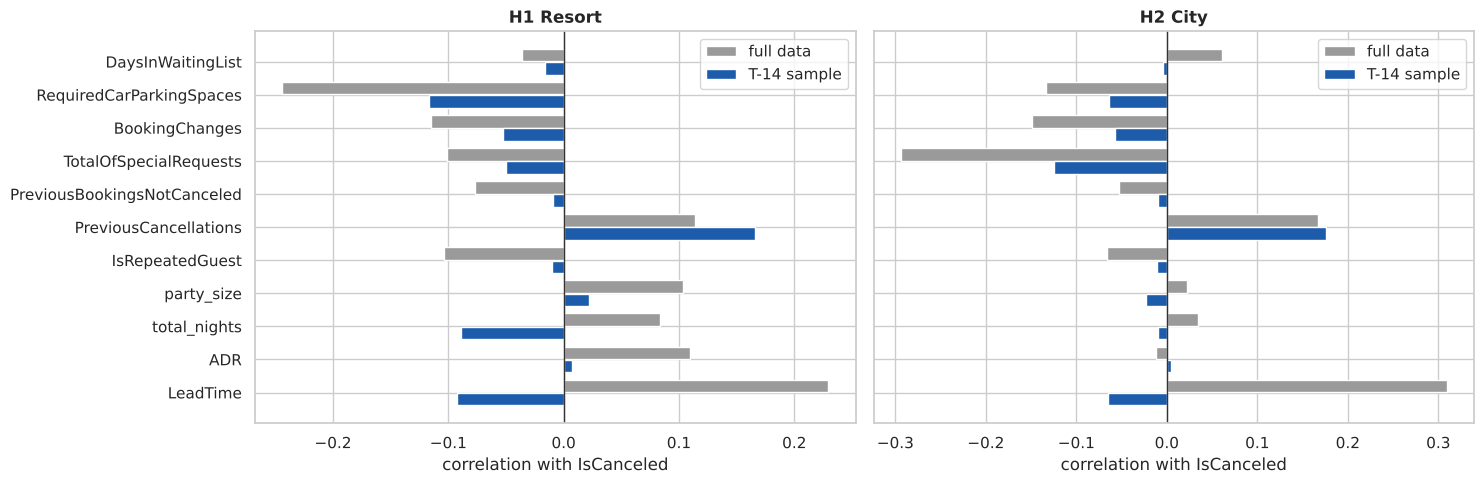

In [39]:
corr_cols = ['LeadTime', 'ADR', 'total_nights', 'party_size', 'IsRepeatedGuest',
             'PreviousCancellations', 'PreviousBookingsNotCanceled', 'TotalOfSpecialRequests',
             'BookingChanges', 'RequiredCarParkingSpaces', 'DaysInWaitingList']
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, h in zip(axes, ['H1', 'H2']):
    a = full[full.hotel == h][corr_cols].corrwith(full[full.hotel == h].IsCanceled)
    b = tx[tx.hotel == h][corr_cols].corrwith(tx[tx.hotel == h].IsCanceled)
    y = np.arange(len(corr_cols))
    ax.barh(y + 0.2, a, height=0.38, color=FULL_COLOR, label='full data')
    ax.barh(y - 0.2, b, height=0.38, color=TX_COLOR, label='T-14 sample')
    ax.axvline(0, color='#333', lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(corr_cols)
    ax.set_xlabel('correlation with IsCanceled')
    ax.set_title(HOTEL_NAMES[h], fontweight='bold')
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: correlation
- **LeadTime** has a positive correlation in the full data (0.23 for H1, 0.31 for H2) but a **negative** one in the T-14 sample (-0.09 and -0.07). Same flip as in Section 10.1.
- **PreviousCancellations** is the strongest positive signal at T-14 (0.17 and 0.18).
- The strongest negative signals are **RequiredCarParkingSpaces** (H1) and **TotalOfSpecialRequests** (H2). Both are under suspicion of leakage (Section 11).
- All correlations are weak (below 0.2 in absolute value). The relationship is not linear, so tree models may do better than a linear model.

### 10.7 Guest country

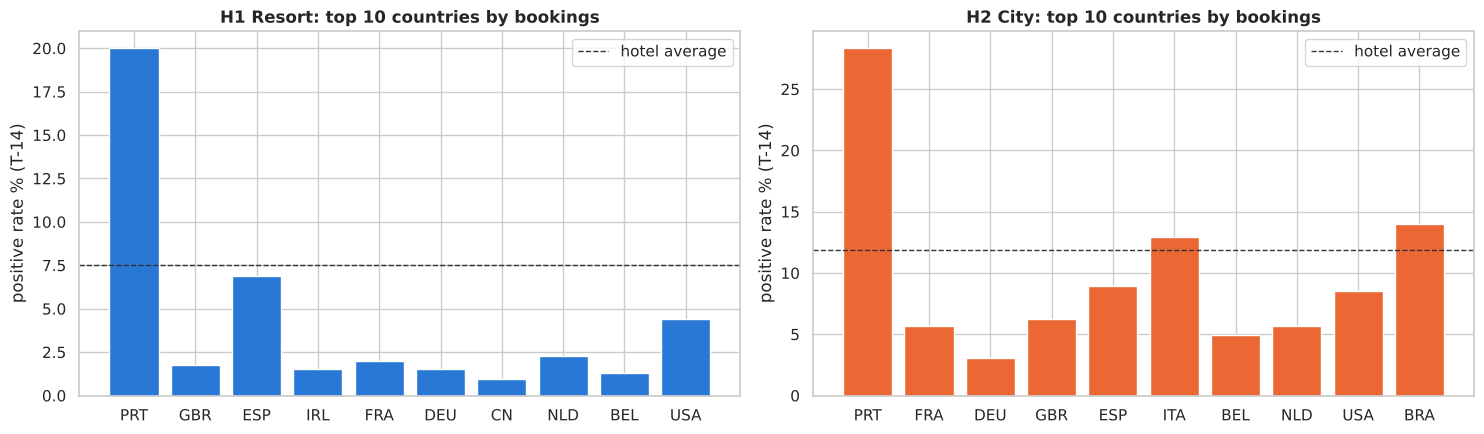

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, h in zip(axes, ['H1', 'H2']):
    t = tx[tx.hotel == h]
    top = t.Country.value_counts().head(10).index
    rate = t[t.Country.isin(top)].groupby('Country').IsCanceled.mean().reindex(top) * 100
    ax.bar(top, rate, color=HOTEL_COLORS[h])
    ax.axhline(t.IsCanceled.mean() * 100, color='#333', ls='--', lw=1, label='hotel average')
    ax.set_ylabel('positive rate % (T-14)')
    ax.set_title(f'{HOTEL_NAMES[h]}: top 10 countries by bookings', fontweight='bold')
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: country
- **Portugal (PRT)** stands out: its T-14 positive rate is **20.0% (H1) and 28.3% (H2)**, about 2.5 times the hotel average. All other large countries are much lower (for example GBR 1.8% in H1, FRA 5.6% in H2).
- This gap is too big to be only guest behaviour. It matches a known issue in this dataset: country is confirmed at check-in, so cancelled bookings often keep the default value PRT. See the leakage audit in Section 11.

## 11. Leakage audit: which columns are safe at T-14?

The data shows each booking in its **final state**: at check-in or check-out for completed stays, and at cancellation for cancelled ones. A column that is filled or updated at check-in will look different for the two labels for a reason the model cannot know at T-14. That is leakage. The model would look great offline and fail in production.

For each suspicious column we check a simple condition inside the T-14 sample.

**How to read the table**
- `% of label 0 where true` and `% of label 1 where true`: how common the condition is within each label.
- `positive rate when true %`: among bookings where the condition is true, the share with label 1. Compare it with `base positive rate %`.
- A value far from the base rate means the condition separates the labels. If the condition is only known at check-in, that separation is leakage.

In [41]:
conditions = {
    'AssignedRoomType != ReservedRoomType': tx.AssignedRoomType != tx.ReservedRoomType,
    'BookingChanges > 0':                   tx.BookingChanges > 0,
    'RequiredCarParkingSpaces > 0':         tx.RequiredCarParkingSpaces > 0,
    'TotalOfSpecialRequests > 0':           tx.TotalOfSpecialRequests > 0,
    'DaysInWaitingList > 0':                tx.DaysInWaitingList > 0,
    'Country == PRT':                       tx.Country == 'PRT',
    'Country missing':                      tx.Country.isna(),
    'Agent == NULL':                        tx.Agent.astype(str) == 'NULL',
    'Company == NULL':                      tx.Company.astype(str) == 'NULL',
    'ADR <= 0':                             tx.ADR <= 0,
}
rows = []
for name, cond in conditions.items():
    for h in ['H1', 'H2']:
        in_h = tx.hotel == h
        lab = tx.IsCanceled
        rows.append({'condition': name, 'hotel': h,
                     '% of label 0 where true': cond[in_h & (lab == 0)].mean() * 100,
                     '% of label 1 where true': cond[in_h & (lab == 1)].mean() * 100,
                     'positive rate when true %': lab[in_h & cond].mean() * 100,
                     'base positive rate %': lab[in_h].mean() * 100})
audit = pd.DataFrame(rows).set_index(['condition', 'hotel']).round(1)
audit

% of label 0 where true  % of label 1 where true  positive rate when true %  base positive rate %
condition                            hotel                                                                                                   
AssignedRoomType != ReservedRoomType H1                        19.9                      8.2                        3.2                   7.5
                                     H2                        13.7                      4.3                        4.0                  11.8
BookingChanges > 0                   H1                        26.5                     16.2                        4.7                   7.5
                                     H2                        18.8                      9.9                        6.6                  11.8
RequiredCarParkingSpaces > 0         H1                        16.2                      0.0                        0.0                   7.5
                                     H2                         3.4                      0.0                        0.0                  11.8
TotalOfSpecialRequests > 0           H1                        51.1                     41.5                        6.2                   7.5
                                     H2                        55.7                     33.7                        7.5                  11.8
DaysInWaitingList > 0                H1                         1.3                      0.5                        2.9                   7.5
                                     H2                         3.2                      3.0                       11.0                  11.8
Country == PRT                       H1                        23.8                     73.5                       20.0                   7.5
                                     H2                        17.6                     51.9                       28.3                  11.8
Country missing                      H1                         0.5                      0.6                        9.3                   7.5
                                     H2                         0.0                      0.0                        NaN                  11.8
Agent == NULL                        H1                        14.5                     17.1                        8.7                   7.5
                                     H2                         5.4                      7.4                       15.6                  11.8
Company == NULL                      H1                        93.7                     94.4                        7.5                   7.5
                                     H2                        97.1                     97.1                       11.8                  11.8
ADR <= 0                             H1                         1.5                      1.6                        7.6                   7.5
                                     H2                         0.9                      0.6                        8.1                  11.8

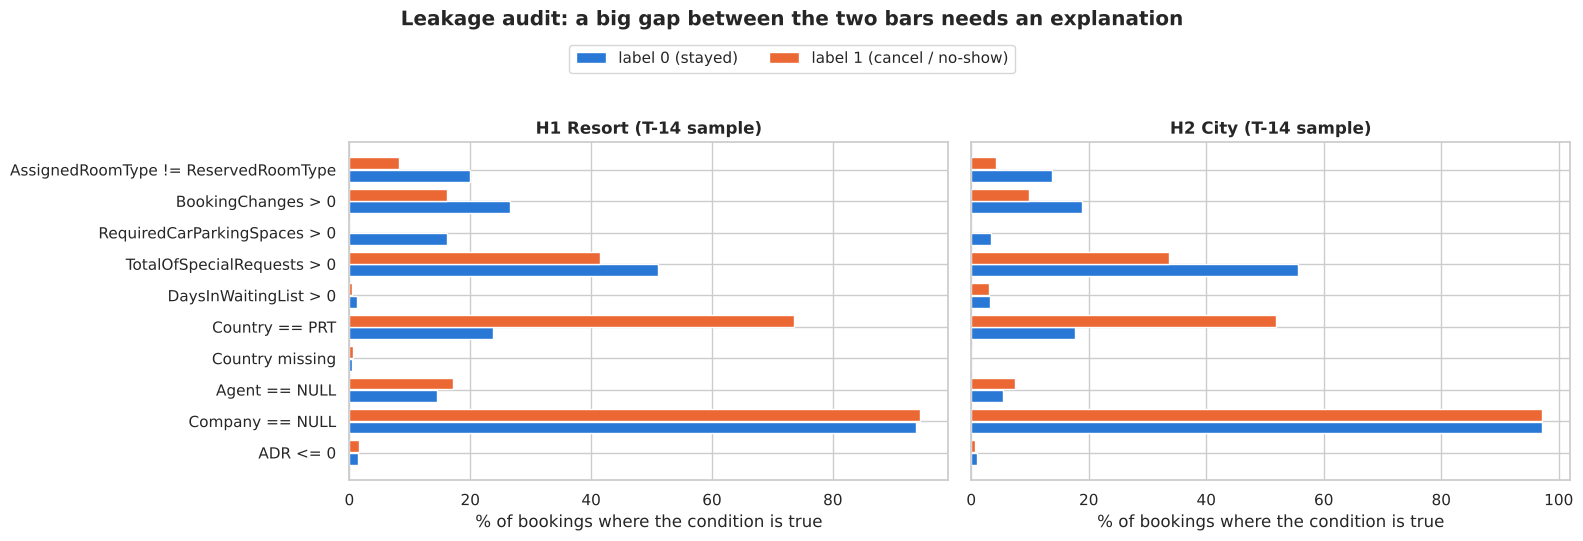

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
names_list = list(conditions.keys())
y = np.arange(len(names_list))
for ax, h in zip(axes, ['H1', 'H2']):
    a = audit.xs(h, level='hotel').reindex(names_list)
    ax.barh(y + 0.2, a['% of label 0 where true'], height=0.38, color=LABEL_COLORS[0], label='label 0 (stayed)')
    ax.barh(y - 0.2, a['% of label 1 where true'], height=0.38, color=LABEL_COLORS[1], label='label 1 (cancel / no-show)')
    ax.set_yticks(y)
    ax.set_yticklabels(names_list)
    ax.set_xlabel('% of bookings where the condition is true')
    ax.set_title(f'{HOTEL_NAMES[h]} (T-14 sample)', fontweight='bold')
axes[0].invert_yaxis()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.93), ncol=2)
plt.suptitle('Leakage audit: a big gap between the two bars needs an explanation', fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

### Observation: leakage evidence
- **RequiredCarParkingSpaces > 0 never happens for label 1.** The positive rate when true is **0.0%** against a base of 7.5% (H1) and 11.8% (H2). Parking is recorded at arrival. This is a perfect leak and **must be excluded**.
- **AssignedRoomType != ReservedRoomType** is 2 to 3 times more common for label 0 (19.9% vs 8.2% for H1). The room is assigned at check-in. **Exclude.**
- **Country == PRT** covers **74% of H1 positives but only 24% of completed stays** (H2: 52% vs 18%). The positive rate for PRT is **20.0% (H1) and 28.3% (H2)**, about 2.5 times the base rate. Country is confirmed at check-in and cancelled bookings often keep the default PRT. Using Country as it is would leak the label. **Risky:** drop it, or keep a coarse version and test the effect.
- **BookingChanges** and **TotalOfSpecialRequests** are higher for completed stays. Part of this is real commitment, part is changes made after T-14 or at check-in. **Risky:** train with and without them and compare.
- **DaysInWaitingList, Agent, Company and ADR** show small differences. Keep them as risky and monitor.

In [43]:
feature_status = pd.DataFrame([
    ['LeadTime', 'safe', 'Known at booking. Always >= X in the T-14 sample by construction'],
    ['Arrival year / month / week / day', 'safe', 'Known at booking'],
    ['StaysInWeekendNights, StaysInWeekNights', 'safe*', 'Known at booking, can be edited before arrival'],
    ['Adults, Children, Babies', 'safe*', 'Known at booking, can be edited before arrival'],
    ['Meal, ReservedRoomType', 'safe*', 'Known at booking, can be edited before arrival'],
    ['MarketSegment, DistributionChannel, CustomerType', 'safe', 'Booking attributes'],
    ['DepositType', 'safe', 'Booking attribute'],
    ['IsRepeatedGuest, PreviousCancellations, PreviousBookingsNotCanceled', 'safe', 'Guest history before the booking'],
    ['ADR', 'risky', 'Final price, may be changed after T-14. Use with care'],
    ['Agent, Company', 'risky', 'Can be filled or changed later'],
    ['TotalOfSpecialRequests', 'risky', 'Requests can be added close to or at check-in'],
    ['DaysInWaitingList', 'risky', 'Final value, timing unknown'],
    ['BookingChanges', 'risky', 'Final count includes changes after T-14 and at check-in'],
    ['Country', 'risky', 'Often confirmed at check-in. See the PRT pattern above'],
    ['RequiredCarParkingSpaces', 'exclude', 'Recorded at arrival. Zero for every cancellation'],
    ['AssignedRoomType', 'exclude', 'Assigned at check-in. Not known at T-14'],
    ['ReservationStatus, ReservationStatusDate', 'exclude', 'Define the sample and the label'],
], columns=['column(s)', 'status at T-14', 'reason'])
feature_status

,column(s),status at T-14,reason
0,LeadTime,safe,Known at booking. Always >= X in the T-14 samp...
1,Arrival year / month / week / day,safe,Known at booking
2,"StaysInWeekendNights, StaysInWeekNights",safe*,"Known at booking, can be edited before arrival"
3,"Adults, Children, Babies",safe*,"Known at booking, can be edited before arrival"
4,"Meal, ReservedRoomType",safe*,"Known at booking, can be edited before arrival"
5,"MarketSegment, DistributionChannel, CustomerType",safe,Booking attributes
6,DepositType,safe,Booking attribute
7,"IsRepeatedGuest, PreviousCancellations, Previo...",safe,Guest history before the booking
8,ADR,risky,"Final price, may be changed after T-14. Use wi..."
9,"Agent, Company",risky,Can be filled or changed later


### Proposed feature status

- **safe**: known at booking time and does not change.
- **safe\***: known at booking time but can be edited before arrival. We only have the final value. This is a small risk that we accept and document.
- **risky**: may be updated after T-14. Train the model with and without these columns and compare.
- **exclude**: never used as a feature.

This table is the starting point for the feature definition in the pipeline. Any change should be agreed by the team and versioned.

## 12. Time patterns

### 12.1 Yearly volume and cancellation rate

In [44]:
yearly = df.groupby(['hotel', 'ArrivalDateYear']).agg(
    bookings=('IsCanceled', 'size'),
    arrival_months=('ArrivalDateMonth', 'nunique'),
    cancel_rate_pct=('IsCanceled', 'mean'))
yearly['cancel_rate_pct'] = (yearly['cancel_rate_pct'] * 100).round(1)
yearly

bookings  arrival_months  cancel_rate_pct
hotel ArrivalDateYear                                           
H1    2015                 8314               6             25.7
      2016                18567              12             26.6
      2017                13179               8             30.8
H2    2015                13682               6             43.9
      2016                38140              12             40.4
      2017                27508               8             42.5

### Observation: yearly view
- 2015 has only 6 months (July to December) and 2017 only 8 months (January to August). Yearly totals are not comparable.
- H1 cancellation rate rises from 25.7% (2015) to 30.8% (2017). H2 stays around 40 to 44%.
- Because the data has a clear time order and the mix changes over time, any train and test split must be **by time, not random**.

### 12.2 Days with mass cancellations

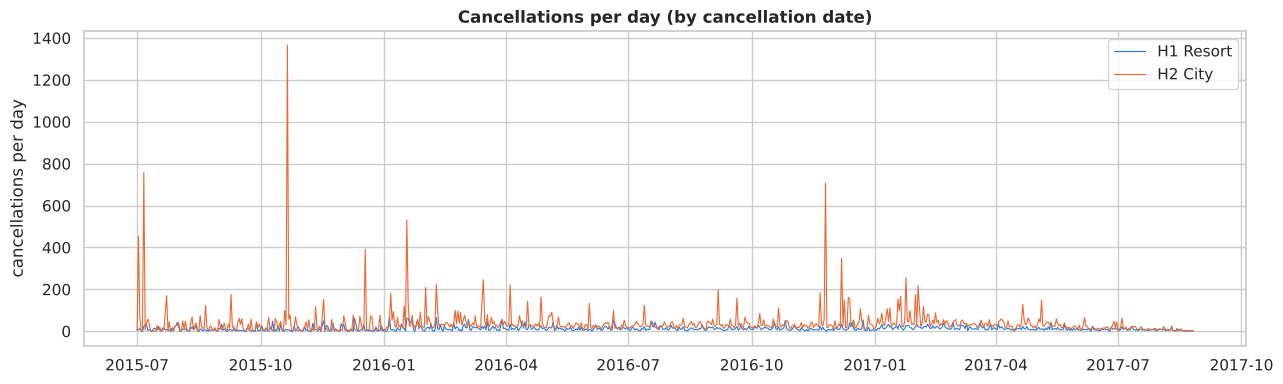

H1 Resort: median 9 cancellations per day. Top 5 days:
                       cancellations  arrival_dates_hit  non_refund_pct    top_segment
ReservationStatusDate                                                                 
2015-01-21                        91                  2              99         Groups
2015-06-17                        89                 18              45  Offline TA/TO
2016-01-05                        70                 15              71         Groups
2016-02-09                        67                 13              75         Groups
2016-01-19                        63                 17              38         Groups

H2 City: median 25 cancellations per day. Top 5 days:
                       cancellations  arrival_dates_hit  non_refund_pct    top_segment
ReservationStatusDate                                                                 
2015-10-21                      1365                 59              99         Groups
2015-01-01          

In [45]:
daily = canc.groupby(['hotel', 'ReservationStatusDate']).agg(
    cancellations=('booking_id', 'count'),
    arrival_dates_hit=('arrival_date', 'nunique'),
    non_refund_pct=('DepositType', lambda s: round((s == 'Non Refund').mean() * 100)),
    top_segment=('MarketSegment', lambda s: s.value_counts().index[0]))

fig, ax = plt.subplots(figsize=(13, 4))
for h in ['H1', 'H2']:
    s = daily.loc[h, 'cancellations'].asfreq('D', fill_value=0)
    s = s[s.index >= '2015-07-01']
    ax.plot(s.index, s.values, color=HOTEL_COLORS[h], lw=0.8, label=HOTEL_NAMES[h])
ax.set_ylabel('cancellations per day')
ax.set_title('Cancellations per day (by cancellation date)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

for h in ['H1', 'H2']:
    d = daily.loc[h]
    print(f'{HOTEL_NAMES[h]}: median {d.cancellations.median():.0f} cancellations per day. Top 5 days:')
    print(d.sort_values('cancellations', ascending=False).head(5).to_string())
    print()

### Observation: mass cancellation days
- On a normal day H1 has about **9 cancellations** and H2 about **25**. But the top days reach **91 (H1) and 1,365 (H2)**.
- The biggest days are driven by **Groups** and **Offline TA/TO**, often with **Non Refund** deposits (up to 99%), and they hit many arrival dates at once. This looks like an agent or tour operator releasing blocked rooms.
- These spikes are real business events, not data errors. Monitoring on daily cancellation counts must expect them, otherwise it will raise false alarms.
- Over 97% of the cancellations on the top 5 days happen 14 or more days before arrival, so they are removed by the T-14 rule and do not reach the model.

### 12.3 Booking mix over time

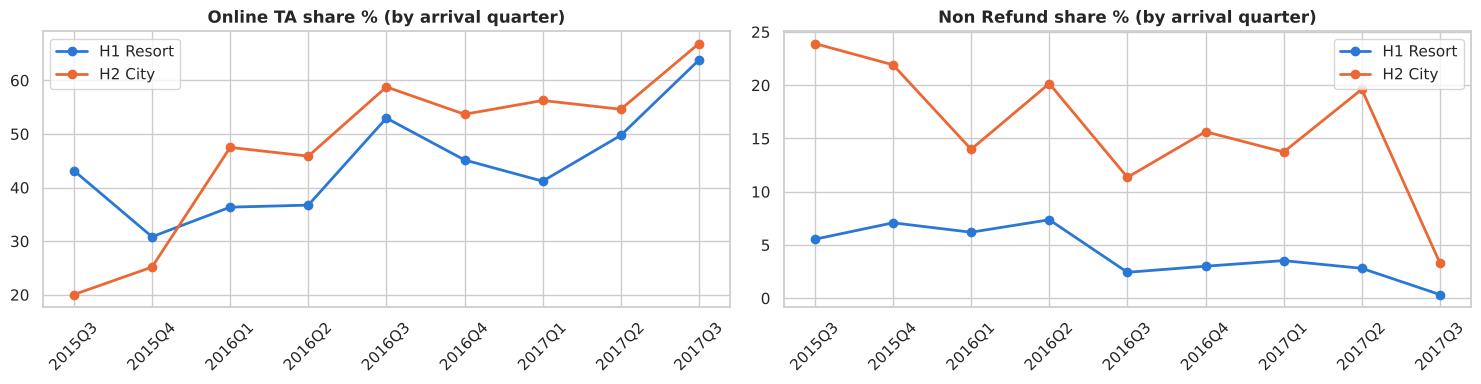

In [46]:
q = df.assign(quarter=df.arrival_date.dt.to_period('Q').astype(str))
mix = q.groupby(['hotel', 'quarter']).agg(
    online_ta_pct=('MarketSegment', lambda s: (s == 'Online TA').mean() * 100),
    non_refund_pct=('DepositType', lambda s: (s == 'Non Refund').mean() * 100))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, col, title in zip(axes, ['online_ta_pct', 'non_refund_pct'], ['Online TA share %', 'Non Refund share %']):
    for h in ['H1', 'H2']:
        s = mix.loc[h, col]
        ax.plot(s.index, s.values, marker='o', color=HOTEL_COLORS[h], lw=2, label=HOTEL_NAMES[h])
    ax.set_title(title + ' (by arrival quarter)', fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: booking mix changes over time
- **Online TA share grows** in both hotels: H1 from 43% to 64% and H2 from 20% to 67% (Q3 2015 to Q3 2017).
- **Non Refund share falls**, most of all in H2 (from 24% to 3%).
- This is a real change in the booking mix (data drift). A model trained on older data may see a different mix in production. This is a good example for the monitoring part of the project.

## 13. Summary

### Key findings

**Data quality**
- The data is clean. Only 28 out of 119,390 rows have small date mismatches. `NULL` in Agent and Company means "none".
- ADR has a few zero, negative and extreme values. 180 bookings have 0 guests. These need cleaning rules.
- 21% (H1) and 40% (H2) of rows are identical to another row. They are kept as separate bookings.

**Prediction setup (T-14)**
- Cutoff = arrival date - 14 days. A booking is scored if it was created by the cutoff and was not cancelled or a no-show by the cutoff.
- Label 1 = cancelled or no-show after the cutoff. Label 0 = completed stay.
- `ReservationStatus` and `ReservationStatusDate` only define the sample and the label.

**Choice of X**

| X | H1 positive rate | H2 positive rate | H1 positives | H2 positives | No-show share of positives |
|---|---|---|---|---|---|
| 3 | 2.5% | 3.8% | 612 | 1,628 | 35 to 46% |
| 7 | 4.2% | 7.6% | 927 | 3,085 | 21 to 22% |
| **14** | **7.5%** | **11.8%** | **1,522** | **4,543** | **10 to 13%** |
| 30 | 12.3% | 18.3% | 2,199 | 6,329 | 5 to 8% |

We suggest **X = 14**: enough positives, a label driven by real cancellations, and two weeks for the hotel to act.

**Rooms**
- Room type cannot tell the number of guests (H1 room type A has 0 to 55 guests).
- Room assumption: rooms = adults / 2, rounded up, minimum 1. Children and babies share the parents' room. This gives 1.04 (H1) and 1.06 (H2) rooms per booking.

**Feature behaviour in the T-14 sample**
- Lead time flips: short-lead bookings are the riskiest in the T-14 sample (the opposite of the full data).
- Non Refund and Groups mostly cancel before the cutoff, so they matter much less in the T-14 sample.
- PreviousCancellations, DepositType, MarketSegment, CustomerType and arrival month carry signal.

**Leakage**
- Exclude: `RequiredCarParkingSpaces`, `AssignedRoomType`, `ReservationStatus`, `ReservationStatusDate`.
- Risky, test with and without: `Country`, `BookingChanges`, `TotalOfSpecialRequests`, `DaysInWaitingList`, `Agent`, `Company`, `ADR`.

**Time**
- H2 July and August 2015 look incomplete (kept, with a warning).
- Strong seasonality, mass cancellation days and a changing booking mix (Online TA up, Non Refund down). Splits must be by time.


In [95]:
# Data cleaning plan: one row per column (or per check)
kids = df['Children'].fillna(0) + df['Babies']
no_check = pd.Series(False, index=df.index)

checks = [
    # column, check, rows flagged, what to pay attention, next step in cleaning
    ('IsCanceled', 'none', no_check,
     'Target. Must match ReservationStatus', 'Keep as label only'),
    ('LeadTime', '> 365 days', df.LeadTime > 365,
     'Long tail up to 737 days', 'Keep. Cap at 99th percentile for modelling'),
    ('ArrivalDateYear / Month / Week / Day', 'none', no_check,
     'Month is text. Build arrival_date from year + month + day', 'Create arrival_date'),
    ('StaysInWeekendNights + StaysInWeekNights', 'total nights = 0', df.total_nights == 0,
     'Day use bookings (0 nights)', 'Keep. Flag as day use'),
    ('StaysInWeekendNights + StaysInWeekNights', 'total nights > 30', df.total_nights > 30,
     'Very long stays, max 69 nights', 'Keep. Flag'),
    ('Adults', 'Adults = 0', df.Adults == 0,
     'Booking without an adult', 'Flag. Count as 1 room'),
    ('Adults', 'Adults > 4', df.Adults > 4,
     'Group bookings, up to 55 adults in one row', 'Keep. Room assumption handles them'),
    ('Children', 'missing', df.Children.isna(),
     '4 empty cells in H2', 'Fill with 0'),
    ('Children', 'Children > 3', df.Children > 3,
     'One booking with 10 children', 'Remove'),
    ('Babies', 'Babies > 2', df.Babies > 2,
     'Values 9 and 10 are data errors', 'Remove'),
    ('Adults + Children + Babies', 'no guests at all', df.party_size == 0,
     'Not a real stay', 'Remove'),
    ('Adults + Children + Babies', 'children or babies but 0 adults', (df.Adults == 0) & (kids > 0),
     'Possible entry error', 'Flag'),
    ('Meal', 'Undefined', df.Meal == 'Undefined',
     'Same meaning as SC (no meal)', 'Merge into SC'),
    ('Country', 'missing', df.Country.isna(),
     'Also a leakage risk (PRT default)', 'Set to Unknown. Decide drop or coarse version'),
    ('MarketSegment', 'Undefined', df.MarketSegment == 'Undefined',
     'Only 2 rows', 'Merge into Other'),
    ('DistributionChannel', 'Undefined', df.DistributionChannel == 'Undefined',
     'Only 5 rows', 'Merge into Other'),
    ('IsRepeatedGuest', 'repeated but no history',
     (df.IsRepeatedGuest == 1) & (df.PreviousCancellations + df.PreviousBookingsNotCanceled == 0),
     'Conflicts with history columns', 'Keep. Log as warning'),
    ('IsRepeatedGuest', 'not repeated but has earlier stays',
     (df.IsRepeatedGuest == 0) & (df.PreviousBookingsNotCanceled > 0),
     'Conflicts with history columns', 'Keep. Log as warning'),
    ('PreviousCancellations', '> 10', df.PreviousCancellations > 10,
     'Max 26, often group or agent bookings', 'Keep. Cap for modelling'),
    ('PreviousBookingsNotCanceled', '> 10', df.PreviousBookingsNotCanceled > 10,
     'Max 72, loyal or corporate guests', 'Keep. Cap for modelling'),
    ('ReservedRoomType', 'none', no_check,
     'Does not tell number of guests', 'Use as category only'),
    ('AssignedRoomType', 'none', no_check,
     'Set at check-in (leakage)', 'Drop'),
    ('BookingChanges', '> 10', df.BookingChanges > 10,
     'Final count, includes changes after T-14 (risky)', 'Keep for test with and without'),
    ('DepositType', 'none', no_check,
     'Non Refund mostly cancels before T-14', 'Keep'),
    ('Agent', '"NULL"', df.Agent.astype(str) == 'NULL',
     'NULL means no agent. High number of IDs', 'Replace NULL with none. Group rare IDs'),
    ('Company', '"NULL"', df.Company.astype(str) == 'NULL',
     'NULL in 92 to 95% of rows', 'Replace NULL with none, or use has_company flag'),
    ('DaysInWaitingList', '> 100', df.DaysInWaitingList > 100,
     'Max 391, timing unknown (risky)', 'Keep. Cap for modelling'),
    ('CustomerType', 'none', no_check,
     'Clean, 4 values', 'Keep'),
    ('ADR', '< 0', df.ADR < 0,
     'Negative price is an error', 'Remove'),
    ('ADR', '= 0 and not Complementary', (df.ADR == 0) & (df.MarketSegment != 'Complementary'),
     'Free stay without a reason', 'Flag'),
    ('ADR', '> 500', df.ADR > 500,
     '5,400 in H2 is an error. About 510 is plausible', 'Remove 5,400. Cap the rest'),
    ('RequiredCarParkingSpaces', '> 2', df.RequiredCarParkingSpaces > 2,
     'Recorded at arrival (perfect leak)', 'Drop column'),
    ('TotalOfSpecialRequests', 'none', no_check,
     'Range 0 to 5. Can be added late (risky)', 'Keep for test with and without'),
    ('ReservationStatus / ReservationStatusDate', 'dates do not match',
     ((df.ReservationStatus == 'No-Show') & (df.status_gap_days != 0))
     | ((df.ReservationStatus == 'Check-Out') & (df.status_gap_days != -df.total_nights)),
     'Only used to build sample and label', 'Keep rows. Log as warning. Never a feature'),
    ('All columns', 'row identical to another row', df.duplicated(subset=source_cols, keep=False),
     '21% (H1) and 40% (H2), may be group bookings', 'Keep as separate bookings'),
]

rows = []
for col, check, mask, attention, action in checks:
    rows.append({'column': col,
                 'check': check,
                 'H1 rows': int(mask[df.hotel == 'H1'].sum()),
                 'H2 rows': int(mask[df.hotel == 'H2'].sum()),
                 'pay attention': attention,
                 'next step': action})
cleaning_plan = pd.DataFrame(rows)

pd.set_option('display.max_colwidth', 80)
cleaning_plan

,column,check,H1 rows,H2 rows,pay attention,next step
0,IsCanceled,none,0,0,Target. Must match ReservationStatus,Keep as label only
1,LeadTime,> 365 days,444,2704,Long tail up to 737 days,Keep. Cap at 99th percentile for modelling
2,ArrivalDateYear / Month / Week / Day,none,0,0,Month is text. Build arrival_date from year + month + day,Create arrival_date
3,StaysInWeekendNights + StaysInWeekNights,total nights = 0,384,331,Day use bookings (0 nights),Keep. Flag as day use
4,StaysInWeekendNights + StaysInWeekNights,total nights > 30,17,7,"Very long stays, max 69 nights",Keep. Flag
5,Adults,Adults = 0,13,390,Booking without an adult,Flag. Count as 1 room
6,Adults,Adults > 4,16,0,"Group bookings, up to 55 adults in one row",Keep. Room assumption handles them
7,Children,missing,0,4,4 empty cells in H2,Fill with 0
8,Children,Children > 3,1,0,One booking with 10 children,Remove
9,Babies,Babies > 2,0,2,Values 9 and 10 are data errors,Remove
